<a href="https://colab.research.google.com/github/dhivyamohan92/Washington-Health-Insurance-Marketplace-Qualified-Health-Plan-Data-Analysis/blob/main/Washington_QHP_Collab_file_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Washington State Qualified Health Plan (QHP) Data Analysis Using Python

## 1. Project Overview

This project focuses on analyzing Qualified Health Plans (QHPs) in Washington State, USA, using health insurance marketplace data. The analysis covers plan characteristics, insurance rates, covered benefits, provider networks, service areas, and business rules.

The objective is to understand the variety of health insurance plans available in the dataset, compare their characteristics, examine coverage and cost-related information, and identify patterns that may help consumers, analysts, and healthcare business stakeholders better understand the health insurance marketplace.

## 2. Key Areas of Analysis

### 1. Health Insurance Plan Analysis
- Analyze the total number of available plans in the dataset.
- Examine plan distribution by plan type, metal level, issuer, and market coverage.
- Compare plan characteristics across available categories.
- Identify the most common plan types and metal levels.

### 2. Insurance Rates and Cost Analysis
- Examine available insurance rates and premium-related information.
- Compare rates across plans, age groups, geographic areas, or other relevant categories when supported by the data.
- Investigate differences in insurance costs across plan categories.
- Identify unusually high or low rates and examine their potential significance.

### 3. Plan Affordability and Financial Coverage
- Analyze deductibles, maximum out-of-pocket limits, and actuarial values where available.
- Compare financial responsibility across different plan categories.
- Examine how cost-sharing characteristics differ between metal levels.
- Identify missing or incomplete financial information that limits affordability comparisons.

### 4. Health Benefits and Coverage Analysis
- Examine the healthcare benefits included in different plans.
- Compare benefit availability and coverage characteristics across plans.
- Identify common and less common benefits.
- Investigate differences in coverage-related details using the Benefits worksheet.

### 5. Provider Network Analysis
- Analyze the provider networks associated with health insurance plans.
- Examine the distribution of available networks and their relationships with plans.
- Identify plans associated with different network configurations where the data supports this analysis.
- Understand the limitations of the dataset when assessing provider access.

### 6. Geographic Service Area Analysis
- Examine the geographic service areas covered by the listed plans.
- Analyze plan availability across the geographic areas represented in the dataset.
- Compare service-area coverage across plans and issuers where possible.
- Identify geographic coverage gaps in the dataset without assuming that missing records represent an actual lack of coverage.

### 7. Business Rules and Plan Validation
- Examine the business rules recorded in the workbook.
- Understand how the available rules relate to plans and other data tables.
- Identify rule patterns, restrictions, or validation requirements documented in the data.
- Investigate inconsistencies between related records where meaningful comparisons are possible.

### 8. Data Quality and Reliability Analysis
- Assess the completeness and consistency of plan, rate, benefit, network, and service-area information.
- Quantify missing values and duplicate records.
- Investigate inconsistent categories, invalid values, and unusual observations.
- Evaluate how data-quality issues may affect the reliability of analytical findings.

## 3. Key Business Questions

1. What types of Qualified Health Plans are represented in the Washington State dataset?
2. Which plan types and metal levels appear most frequently?
3. How do insurance rates vary across the available plans and categories?
4. What differences exist in deductibles, out-of-pocket limits, and actuarial values?
5. Which healthcare benefits are most frequently represented?
6. How are provider networks associated with the available plans?
7. Which geographic service areas are represented in the dataset?
8. What patterns and restrictions are documented in the business rules?
9. Which cost and coverage comparisons can be supported reliably by the available data?
10. What data-quality issues should be considered before drawing conclusions?

## 4. Expected Analytical Outcomes

- A detailed understanding of Washington State QHP plan characteristics.
- Comparisons of available insurance rates and financial coverage measures.
- Insights into healthcare benefits, provider networks, and geographic service areas.
- Identification of patterns, unusual values, and data-quality limitations.
- Evidence-based findings that explain differences between plan categories.
- Clear visualizations and a summary of the most meaningful results.

## 5. Dataset and Tools

**Dataset:** `Washington_QHP_Cleaned (1).xlsx`

**Worksheets:** Plans, Rates, Benefits, Networks, ServiceAreas, BusinessRules

**Domain:** US Healthcare — Health Insurance Marketplace

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab

**Note:** All findings will be based on the fields and records available in the workbook. Premium comparisons, geographic analysis, benefit comparisons, and other business questions will be finalized after verifying the relevant columns and data quality. Missing information will not be interpreted as zero or as proof that a plan does not provide a particular benefit or service.

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd

file_path = "https://raw.githubusercontent.com/dhivyamohan92/Washington-Health-Insurance-Marketplace-Qualified-Health-Plan-Data-Analysis/04a48795373eb8da8a487e3e2cb3b782fe432382/Washington_QHP_Analysis_Ready.xlsx"

excel_file = pd.ExcelFile(file_path)

print("Worksheets:", excel_file.sheet_names)
print("Total worksheets:", len(excel_file.sheet_names))

for sheet_name in excel_file.sheet_names:
    sheet_df = pd.read_excel(excel_file, sheet_name=sheet_name)
    print(f"{sheet_name}: {sheet_df.shape[0]} rows, {sheet_df.shape[1]} columns")

Worksheets: ['README', 'Plans', 'Rates', 'Benefits', 'Networks', 'ServiceAreas']
Total worksheets: 6
README: 6 rows, 2 columns
Plans: 328 rows, 16 columns
Rates: 28713 rows, 11 columns
Benefits: 23116 rows, 11 columns
Networks: 20 rows, 5 columns
ServiceAreas: 477 rows, 8 columns


In [3]:
# Read the dataset documentation.

readme_df = pd.read_excel(excel_file, sheet_name="README")

display(readme_df)

,Washington QHP Dataset — Analysis Ready,Unnamed: 1
0,Purpose,A reduced-column workbook for a beginner-frien...
1,Sheets,"Plans, Rates, Benefits, Networks, ServiceAreas"
2,Suggested starting point,Start with Plans and Rates. Join using PLAN ID...
3,Analysis ideas,Plan counts by metal level/type; individual pr...
4,Important note,Rates and benefits contain multiple rows per p...
5,Data handling,Original values are retained; only columns wer...


In [4]:
# Load the five worksheets for analysis.

sheet_names = ["Plans", "Rates", "Benefits", "Networks", "ServiceAreas"]

data = {
    sheet: pd.read_excel(excel_file, sheet_name=sheet)
    for sheet in sheet_names
}

for sheet, df_sheet in data.items():
    print(f"{sheet}: {df_sheet.shape[0]} rows, {df_sheet.shape[1]} columns")

Plans: 328 rows, 16 columns
Rates: 28713 rows, 11 columns
Benefits: 23116 rows, 11 columns
Networks: 20 rows, 5 columns
ServiceAreas: 477 rows, 8 columns


In [5]:
# Display column names, data types, and non-null counts for each worksheet.

for sheet, df in data.items():
    print(f"\n--- {sheet} ---")
    df.info()


--- Plans ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 328 entries, 0 to 327
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   ISSUER NAME                      0 non-null      float64
 1   ISSUER ID                        328 non-null    int64  
 2   PLAN ID                          328 non-null    object 
 3   PLAN MARKETING NAME              328 non-null    object 
 4   PLAN TYPE                        328 non-null    object 
 5   METAL LEVEL                      328 non-null    object 
 6   MARKET COVERAGE                  328 non-null    object 
 7   DENTAL ONLY PLAN                 328 non-null    object 
 8   NETWORK ID                       328 non-null    object 
 9   SERVICE AREA ID                  328 non-null    object 
 10  IS HSA ELIGIBLE                  319 non-null    object 
 11  ISSUER ACTUARIAL VALUE           213 non-null    object 
 12  MEHB IN

Initial observations from df.info()
Worksheet	Key observation

Plans	328 plans; ISSUER NAME is entirely missing.

Rates	28,713 records; INDIVIDUAL RATE is complete, but five other rate-related columns are entirely missing.

Benefits	23,116 records; benefit names and coverage indicators are complete, while several limitation fields have missing values.

Networks	20 records; all five columns are complete.

ServiceAreas	477 records; county name has 5 missing values, and ZIP Code is entirely missing.

In [6]:
# Check missing values in Plans
data["Plans"].isnull().sum()


,0
ISSUER NAME,328
ISSUER ID,0
PLAN ID,0
PLAN MARKETING NAME,0
PLAN TYPE,0
METAL LEVEL,0
MARKET COVERAGE,0
DENTAL ONLY PLAN,0
NETWORK ID,0
SERVICE AREA ID,0


In [7]:
# Check duplicate rows in Plans
data["Plans"].duplicated().sum()

np.int64(0)

In [8]:
# View the first 5 rows of the Plans sheet

data["Plans"].head()

,ISSUER NAME,ISSUER ID,PLAN ID,PLAN MARKETING NAME,PLAN TYPE,METAL LEVEL,MARKET COVERAGE,DENTAL ONLY PLAN,NETWORK ID,SERVICE AREA ID,IS HSA ELIGIBLE,ISSUER ACTUARIAL VALUE,MEHB INN TIER 1 INDIVIDUAL MOOP,MEHB DED INN TIER1 INDIVIDUAL,PLAN EFFECTIVE DATE,PLAN EXPIRATION DATE
0,NaN,12435,12435WA0010001-01,Wellpoint Cascade Complete Gold,EPO,Gold,Individual,No,WAN001,WAS001,No,NaN,NaN,NaN,1/1/2026,12/31/2026
1,NaN,12435,12435WA0010001-02,Wellpoint Cascade Complete Gold,EPO,Gold,Individual,No,WAN001,WAS001,No,NaN,NaN,NaN,1/1/2026,12/31/2026
2,NaN,12435,12435WA0010001-03,Wellpoint Cascade Complete Gold,EPO,Gold,Individual,No,WAN001,WAS001,No,NaN,NaN,NaN,1/1/2026,12/31/2026
3,NaN,12435,12435WA0010002-01,Wellpoint Cascade Vital Gold,EPO,Gold,Individual,No,WAN001,WAS001,No,NaN,NaN,NaN,1/1/2026,12/31/2026
4,NaN,12435,12435WA0010002-02,Wellpoint Cascade Vital Gold,EPO,Gold,Individual,No,WAN001,WAS001,No,NaN,NaN,NaN,1/1/2026,12/31/2026


In [9]:
# Remove the completely empty column from Plans

data["Plans"] = data["Plans"].drop(columns=["ISSUER NAME"])

In [10]:
# Check the updated columns

data["Plans"].columns

Index(['ISSUER ID', 'PLAN ID', 'PLAN MARKETING NAME', 'PLAN TYPE',
       'METAL LEVEL', 'MARKET COVERAGE', 'DENTAL ONLY PLAN', 'NETWORK ID',
       'SERVICE AREA ID', 'IS HSA ELIGIBLE', 'ISSUER ACTUARIAL VALUE',
       'MEHB INN TIER 1 INDIVIDUAL MOOP', 'MEHB DED INN TIER1 INDIVIDUAL',
       'PLAN EFFECTIVE DATE', 'PLAN EXPIRATION DATE'],
      dtype='object')

In [11]:
# Count the HSA eligibility values

data["Plans"]["IS HSA ELIGIBLE"].value_counts(dropna=False)

,count
IS HSA ELIGIBLE,
No,239
Yes,80
NaN,9


In [12]:
# Check the available actuarial values

data["Plans"]["ISSUER ACTUARIAL VALUE"].value_counts(dropna=False)

,count
ISSUER ACTUARIAL VALUE,
NaN,115
100.00%,50
71.84%,30
64.97%,26
73.95%,16
87.87%,15
94.86%,15
71.92%,4
62.20%,4


In [13]:
# Remove the % sign and convert actuarial values to numbers

data["Plans"]["ISSUER ACTUARIAL VALUE"] = (
    data["Plans"]["ISSUER ACTUARIAL VALUE"]
    .str.replace("%", "", regex=False)
    .astype(float)
)

# Check the data type and missing values

data["Plans"]["ISSUER ACTUARIAL VALUE"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 328 entries, 0 to 327
Series name: ISSUER ACTUARIAL VALUE
Non-Null Count  Dtype  
--------------  -----  
213 non-null    float64
dtypes: float64(1)
memory usage: 2.7 KB


In [14]:
# Check available MOOP values

data["Plans"]["MEHB INN TIER 1 INDIVIDUAL MOOP"].value_counts(dropna=False)

,count
MEHB INN TIER 1 INDIVIDUAL MOOP,
NaN,319
$450,7
Not Applicable,2


In [15]:
# Check available deductible values

data["Plans"]["MEHB DED INN TIER1 INDIVIDUAL"].value_counts(dropna=False)

,count
MEHB DED INN TIER1 INDIVIDUAL,
NaN,310
$0,7
Not Applicable,4
"$1,750",2
$85,2
$75,1
$100,1
$50,1


In [16]:
# Check the data types of the plan dates

data["Plans"][["PLAN EFFECTIVE DATE", "PLAN EXPIRATION DATE"]].dtypes

,0
PLAN EFFECTIVE DATE,object
PLAN EXPIRATION DATE,object


In [17]:
# Convert plan dates from text to datetime format

data["Plans"]["PLAN EFFECTIVE DATE"] = pd.to_datetime(
    data["Plans"]["PLAN EFFECTIVE DATE"], errors="coerce"
)

data["Plans"]["PLAN EXPIRATION DATE"] = pd.to_datetime(
    data["Plans"]["PLAN EXPIRATION DATE"], errors="coerce"
)

In [18]:
# Check the updated date data types

data["Plans"][["PLAN EFFECTIVE DATE", "PLAN EXPIRATION DATE"]].dtypes

,0
PLAN EFFECTIVE DATE,datetime64[ns]
PLAN EXPIRATION DATE,datetime64[ns]


In [19]:
# Count plans with expiration dates before their effective dates

(
    data["Plans"]["PLAN EXPIRATION DATE"]
    < data["Plans"]["PLAN EFFECTIVE DATE"]
).sum()

np.int64(0)

In [20]:
# Count missing plan expiration dates

data["Plans"]["PLAN EXPIRATION DATE"].isnull().sum()

np.int64(138)

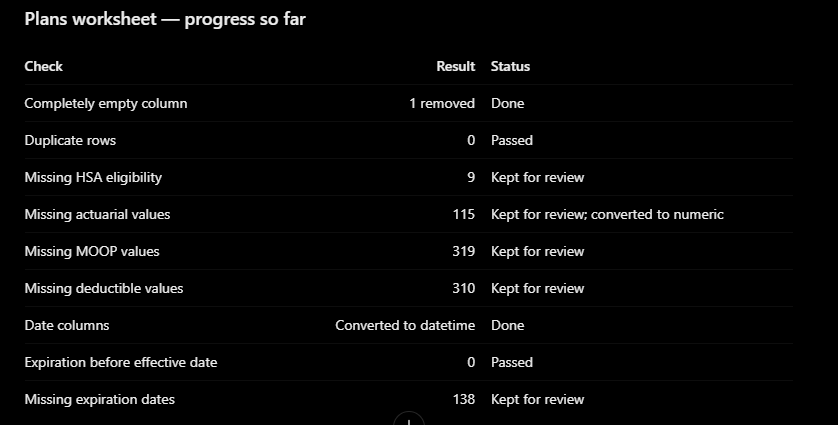

Move to the Rates worksheet

In [21]:
# Check missing values in Rates

data["Rates"].isnull().sum()

,0
ISSUER ID,0
PLAN ID,0
RATING AREA ID,0
TOBACCO,0
AGE,0
INDIVIDUAL RATE,0
INDIVIDUAL TOBACCO RATE,28713
COUPLE,28713
PRIMARY SUBSCRIBER AND ONE DEPENDENT,28713
PRIMARY SUBSCRIBER AND TWO DEPENDENTS,28713


In [22]:
# Check the updated number of rows and columns

data["Rates"].shape

(28713, 11)

In [23]:
# Remove columns where every value is missing

data["Rates"] = data["Rates"].dropna(axis=1, how="all")

In [24]:
data["Rates"].shape

(28713, 6)

In [25]:
# Check duplicate rows in Rates

data["Rates"].duplicated().sum()

np.int64(0)

In [26]:
# View the different age values in Rates

data["Rates"]["AGE"].unique()

array(['0-14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24',
       '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35',
       '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46',
       '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57',
       '58', '59', '60', '61', '62', '63', '64 and over'], dtype=object)

In [27]:
# Summarize individual insurance rates

data["Rates"]["INDIVIDUAL RATE"].describe()

,INDIVIDUAL RATE
count,28713.000000
mean,690.368459
std,443.165146
min,0.000000
25%,432.030000
50%,607.980000
75%,909.050000
max,3067.110000


In [28]:
# Count individual rates equal to zero

(data["Rates"]["INDIVIDUAL RATE"] == 0).sum()

np.int64(828)

In [29]:
# View the first 10 records with zero individual rates

data["Rates"][data["Rates"]["INDIVIDUAL RATE"] == 0].head(10)

,ISSUER ID,PLAN ID,RATING AREA ID,TOBACCO,AGE,INDIVIDUAL RATE
3371,38498,38498WA0310002,Rating Area 1,No Preference,19,0.0
3372,38498,38498WA0310002,Rating Area 1,No Preference,20,0.0
3373,38498,38498WA0310002,Rating Area 1,No Preference,21,0.0
3374,38498,38498WA0310002,Rating Area 1,No Preference,22,0.0
3375,38498,38498WA0310002,Rating Area 1,No Preference,23,0.0
3376,38498,38498WA0310002,Rating Area 1,No Preference,24,0.0
3377,38498,38498WA0310002,Rating Area 1,No Preference,25,0.0
3378,38498,38498WA0310002,Rating Area 1,No Preference,26,0.0
3379,38498,38498WA0310002,Rating Area 1,No Preference,27,0.0
3380,38498,38498WA0310002,Rating Area 1,No Preference,28,0.0


In [30]:
# Count zero-rate records for each plan

data["Rates"].loc[
    data["Rates"]["INDIVIDUAL RATE"] == 0,
    "PLAN ID"
].value_counts().head(10)

,count
PLAN ID,
38498WA0310002,414
58105WA0010002,414


In [31]:
# Check all rates for the two plans with zero rates

data["Rates"][
    data["Rates"]["PLAN ID"].isin(
        ["38498WA0310002", "58105WA0010002"]
    )
].groupby("PLAN ID")["INDIVIDUAL RATE"].describe()

,count,mean,std,min,25%,50%,75%,max
PLAN ID,,,,,,,,
38498WA0310002,459.0,3.773529,11.458170,0.0,0.0,0.0,0.0,38.49
58105WA0010002,459.0,5.208824,15.816383,0.0,0.0,0.0,0.0,53.13


In [32]:
# Find the details of the two plans with zero rates

data["Plans"][
    data["Plans"]["PLAN ID"].isin(
        ["38498WA0310002", "58105WA0010002"]
    )
][["PLAN ID", "PLAN MARKETING NAME", "PLAN TYPE", "METAL LEVEL"]]

,PLAN ID,PLAN MARKETING NAME,PLAN TYPE,METAL LEVEL


In [33]:
# Check whether the two plan IDs exist in Plans

data["Plans"]["PLAN ID"].isin(
    ["38498WA0310002", "58105WA0010002"]
).sum()

np.int64(0)

In [34]:
print(data["Plans"]["PLAN ID"].dtype)
print(data["Rates"]["PLAN ID"].dtype)

object
object


In [35]:
print(data["Plans"]["PLAN ID"].head(10).tolist())
print(data["Rates"]["PLAN ID"].head(10).tolist())

['12435WA0010001-01', '12435WA0010001-02', '12435WA0010001-03', '12435WA0010002-01', '12435WA0010002-02', '12435WA0010002-03', '12435WA0010003-01', '12435WA0010003-02', '12435WA0010003-03', '12435WA0010003-04']
['12435WA0010001', '12435WA0010001', '12435WA0010001', '12435WA0010001', '12435WA0010001', '12435WA0010001', '12435WA0010001', '12435WA0010001', '12435WA0010001', '12435WA0010001']


In [36]:
print(data["Rates"].loc[
    data["Rates"]["INDIVIDUAL RATE"] == 0,
    "PLAN ID"
].unique())

['38498WA0310002' '58105WA0010002']


In [37]:
print(data["Rates"].loc[
    data["Rates"]["INDIVIDUAL RATE"] == 0,
    "ISSUER ID"
].value_counts())

ISSUER ID
38498    414
58105    414
Name: count, dtype: int64


In [38]:
print(data["Plans"]["ISSUER ID"].isin([38498, 58105]).sum())


46


In [39]:
print(data["Plans"].loc[
    data["Plans"]["ISSUER ID"].isin([38498, 58105]),
    ["ISSUER ID", "PLAN ID", "PLAN MARKETING NAME"]
].head(10))

    ISSUER ID            PLAN ID                        PLAN MARKETING NAME
63      38498  38498WA0310002-01  LifeWise Individual Pediatric Dental Plan
64      38498  38498WA0320001-01                    LifeWise Essential Gold
65      38498  38498WA0320001-02                    LifeWise Essential Gold
66      38498  38498WA0320001-03                    LifeWise Essential Gold
67      38498  38498WA0320003-01                  LifeWise Essential Bronze
68      38498  38498WA0320003-02                  LifeWise Essential Bronze
69      38498  38498WA0320003-03                  LifeWise Essential Bronze
70      38498  38498WA0320004-01                  LifeWise Essential Silver
71      38498  38498WA0320004-02                  LifeWise Essential Silver
72      38498  38498WA0320004-03                  LifeWise Essential Silver


In [40]:
print(data["Plans"].loc[
    data["Plans"]["ISSUER ID"].isin([38498, 58105]),
    ["ISSUER ID", "PLAN MARKETING NAME", "PLAN TYPE", "METAL LEVEL"]
].head(15))

    ISSUER ID                        PLAN MARKETING NAME PLAN TYPE  \
63      38498  LifeWise Individual Pediatric Dental Plan       PPO   
64      38498                    LifeWise Essential Gold       EPO   
65      38498                    LifeWise Essential Gold       EPO   
66      38498                    LifeWise Essential Gold       EPO   
67      38498                  LifeWise Essential Bronze       EPO   
68      38498                  LifeWise Essential Bronze       EPO   
69      38498                  LifeWise Essential Bronze       EPO   
70      38498                  LifeWise Essential Silver       EPO   
71      38498                  LifeWise Essential Silver       EPO   
72      38498                  LifeWise Essential Silver       EPO   
73      38498                  LifeWise Essential Silver       EPO   
74      38498                  LifeWise Essential Silver       EPO   
75      38498                  LifeWise Essential Silver       EPO   
76      38498       

In [41]:
print(data["Plans"].loc[
    data["Plans"]["ISSUER ID"] == 58105,
    ["PLAN ID", "PLAN MARKETING NAME", "PLAN TYPE", "METAL LEVEL"]
].head(10))

               PLAN ID                                PLAN MARKETING NAME  \
152  58105WA0010002-01     Delta Dental Individual - Washington Kids Plan   
153  58105WA0110001-01  Delta Dental Individual and Family - Washingto...   

    PLAN TYPE METAL LEVEL  
152       PPO        High  
153       PPO        High  


- Issuer 38498: The zero-rate plan matches LifeWise Individual Pediatric Dental Plan.
- Issuer 58105: The zero-rate plan matches Delta Dental Individual - Washington Kids Plan.
Both are pediatric dental plans, which helps explain why their rates may differ from medical plans. However, we still need to verify why the rates are zero before deciding whether they are valid.
Next step: Check the rates for the two dental plans

In [42]:
print(data["Rates"].loc[
    data["Rates"]["PLAN ID"].isin(
        ["38498WA0310002", "58105WA0010002"]
    ),
    ["PLAN ID", "AGE", "INDIVIDUAL RATE"]
].head(15))

             PLAN ID   AGE  INDIVIDUAL RATE
3366  38498WA0310002  0-14            38.49
3367  38498WA0310002    15            38.49
3368  38498WA0310002    16            38.49
3369  38498WA0310002    17            38.49
3370  38498WA0310002    18            38.49
3371  38498WA0310002    19             0.00
3372  38498WA0310002    20             0.00
3373  38498WA0310002    21             0.00
3374  38498WA0310002    22             0.00
3375  38498WA0310002    23             0.00
3376  38498WA0310002    24             0.00
3377  38498WA0310002    25             0.00
3378  38498WA0310002    26             0.00
3379  38498WA0310002    27             0.00
3380  38498WA0310002    28             0.00


In [43]:
print(data["Rates"].loc[
    data["Rates"]["PLAN ID"] == "58105WA0010002",
    ["AGE", "INDIVIDUAL RATE"]
].head(25))

        AGE  INDIVIDUAL RATE
12240  0-14            53.13
12241    15            53.13
12242    16            53.13
12243    17            53.13
12244    18            53.13
12245    19             0.00
12246    20             0.00
12247    21             0.00
12248    22             0.00
12249    23             0.00
12250    24             0.00
12251    25             0.00
12252    26             0.00
12253    27             0.00
12254    28             0.00
12255    29             0.00
12256    30             0.00
12257    31             0.00
12258    32             0.00
12259    33             0.00
12260    34             0.00
12261    35             0.00
12262    36             0.00
12263    37             0.00
12264    38             0.00


- 38498WA0310002: rate is 38.49 for ages 0–18, then 0.00 from age 19 onward.
- 58105WA0010002: rate is 53.13 for ages 0–18, then 0.00 from age 19 onward.
This repeated pattern suggests the zero rates may be related to the plans' pediatric coverage rather than random data errors.

In [44]:
zero_rates = data["Rates"][data["Rates"]["INDIVIDUAL RATE"] == 0]

print(zero_rates["AGE"].value_counts().sort_index())

AGE
19             18
20             18
21             18
22             18
23             18
24             18
25             18
26             18
27             18
28             18
29             18
30             18
31             18
32             18
33             18
34             18
35             18
36             18
37             18
38             18
39             18
40             18
41             18
42             18
43             18
44             18
45             18
46             18
47             18
48             18
49             18
50             18
51             18
52             18
53             18
54             18
55             18
56             18
57             18
58             18
59             18
60             18
61             18
62             18
63             18
64 and over    18
Name: count, dtype: int64


What we found
- Every age category from 19 through 64 and over has exactly 18 zero-rate records.
- There are 46 age categories in that range.
- \(46 \times 18 = 828\) zero-rate records in total.
- All 828 records belong to the two pediatric dental plan IDs we identified.

In [45]:
print((data["Rates"]["INDIVIDUAL RATE"] < 0).sum())

0


In [46]:
print(data["Rates"].isnull().sum())

ISSUER ID          0
PLAN ID            0
RATING AREA ID     0
TOBACCO            0
AGE                0
INDIVIDUAL RATE    0
dtype: int64


In [47]:
print(data["Rates"]["TOBACCO"].value_counts())

TOBACCO
No Preference    28713
Name: count, dtype: int64


In [48]:
print(data["Rates"]["RATING AREA ID"].nunique())
print(data["Rates"]["RATING AREA ID"].value_counts().sort_index())

9
RATING AREA ID
Rating Area 1    3570
Rating Area 2    4335
Rating Area 3    2805
Rating Area 4    3315
Rating Area 5    3621
Rating Area 6    3570
Rating Area 7    1938
Rating Area 8    2805
Rating Area 9    2754
Name: count, dtype: int64


In [49]:
print(data["Rates"]["INDIVIDUAL RATE"].dtype)

float64


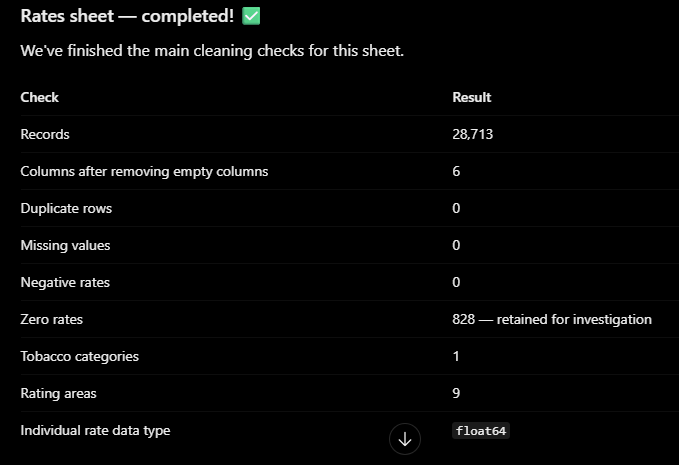

Next: Benefits sheet
Let's start checking the Benefits sheet.

In [50]:

# BENEFITS SHEET: COMPLETE DATA-QUALITY CHECK

df = data["Benefits"]

# 1. Dataset size
print("1. DATASET SIZE")
print("Rows and columns:", df.shape)

# 2. Column names and data types
print("\n2. COLUMN NAMES AND DATA TYPES")
print(df.dtypes)

# 3. Missing values
print("\n3. MISSING VALUES")
print(df.isnull().sum())

# 4. Duplicate rows
print("\n4. DUPLICATE ROWS")
print(df.duplicated().sum())

# 5. Completely empty columns
print("\n5. COMPLETELY EMPTY COLUMNS")
print(df.columns[df.isnull().all()].tolist())

# 6. Unique values in each column
print("\n6. UNIQUE VALUE COUNTS")
print(df.nunique(dropna=True))

# 7. Numeric column summary
print("\n7. NUMERIC COLUMN SUMMARY")
print(df.describe())

# 8. Text column summary
print("\n8. TEXT COLUMN SUMMARY")
print(df.describe(include="object"))

# 9. Check for negative values in numeric columns
print("\n9. NEGATIVE VALUES IN NUMERIC COLUMNS")
numeric_df = df.select_dtypes(include="number")
print((numeric_df < 0).sum())

# 10. Check for zero values in numeric columns
print("\n10. ZERO VALUES IN NUMERIC COLUMNS")
print((numeric_df == 0).sum())

# 11. Check for leading/trailing spaces in text columns
print("\n11. TEXT VALUES WITH EXTRA SPACES")
for col in df.select_dtypes(include="object").columns:
    count = df[col].dropna().apply(
        lambda x: isinstance(x, str) and x != x.strip()
    ).sum()
    if count > 0:
        print(col, ":", count)

print("\nBENEFITS SHEET CHECKS COMPLETED")


1. DATASET SIZE
Rows and columns: (23116, 11)

2. COLUMN NAMES AND DATA TYPES
ISSUER ID                  int64
PLAN ID                   object
BENEFIT NAME              object
IS EHB                    object
IS STATE MANDATE         float64
IS COVERED                object
QUANTITY LIMIT ON SVC     object
LIMIT QUANTITY           float64
LIMIT UNIT                object
EXCLUSIONS                object
EXPLANATION               object
dtype: object

3. MISSING VALUES
ISSUER ID                    0
PLAN ID                      0
BENEFIT NAME                 0
IS EHB                       0
IS STATE MANDATE         23116
IS COVERED                   0
QUANTITY LIMIT ON SVC    16591
LIMIT QUANTITY           18202
LIMIT UNIT               18202
EXCLUSIONS               22886
EXPLANATION              14716
dtype: int64

4. DUPLICATE ROWS
0

5. COMPLETELY EMPTY COLUMNS
['IS STATE MANDATE']

6. UNIQUE VALUE COUNTS
ISSUER ID                 15
PLAN ID                  328
BENEFIT NAME       

In [51]:
# Remove the completely empty column
data["Benefits"] = data["Benefits"].drop(
    columns=["IS STATE MANDATE"]
)

# Confirm the updated dataset size
print(data["Benefits"].shape)

(23116, 10)


In [52]:

# Check benefit categories and limits
df = data["Benefits"]

print("IS EHB:")
print(df["IS EHB"].value_counts(dropna=False))

print("\nIS COVERED:")
print(df["IS COVERED"].value_counts(dropna=False))

print("\nQUANTITY LIMIT ON SVC:")
print(df["QUANTITY LIMIT ON SVC"].value_counts(dropna=False))

print("\nLIMIT UNIT:")
print(df["LIMIT UNIT"].value_counts(dropna=False))

print("\nLIMIT QUANTITY:")
print(df["LIMIT QUANTITY"].value_counts().sort_index())


IS EHB:
IS EHB
Yes    17292
No      5824
Name: count, dtype: int64

IS COVERED:
IS COVERED
Yes    18746
No      4370
Name: count, dtype: int64

QUANTITY LIMIT ON SVC:
QUANTITY LIMIT ON SVC
NaN    16591
Yes     4914
No      1611
Name: count, dtype: int64

LIMIT UNIT:
LIMIT UNIT
NaN                         18202
Days per Month               1276
Days per Year                1228
Visit(s) per Year            1123
Exam(s) per Year              321
Item(s) per Year              319
Days per Lifetime             319
Item(s) per 3 Years           319
Dollars per Year                6
Treatment(s) per 2 Years        2
Treatment(s) per Year           1
Name: count, dtype: int64

LIMIT QUANTITY:
LIMIT QUANTITY
1.0        994
2.0         14
10.0       319
14.0       319
25.0       379
30.0      1957
60.0       391
90.0       216
130.0      319
1000.0       3
2000.0       3
Name: count, dtype: int64


In [53]:

# Check whether service-limit indicators match quantity values

df = data["Benefits"]

print("Quantity limit = Yes:")
print((df["QUANTITY LIMIT ON SVC"] == "Yes").sum())

print("\nQuantity provided:")
print(df["LIMIT QUANTITY"].notna().sum())

print("\nQuantity provided when service limit is No:")
print(
    (
        (df["QUANTITY LIMIT ON SVC"] == "No")
        & df["LIMIT QUANTITY"].notna()
    ).sum()
)

print("\nQuantity missing when service limit is Yes:")
print(
    (
        (df["QUANTITY LIMIT ON SVC"] == "Yes")
        & df["LIMIT QUANTITY"].isna()
    ).sum()
)


Quantity limit = Yes:
4914

Quantity provided:
4914

Quantity provided when service limit is No:
0

Quantity missing when service limit is Yes:
0


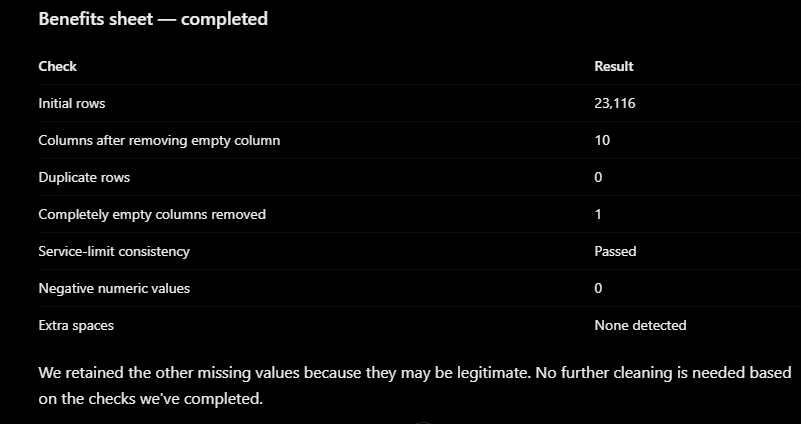

In [54]:

# NETWORKS SHEET: DATA-QUALITY CHECKS

df = data["Networks"]

print("1. DATASET SIZE")
print(df.shape)

print("\n2. COLUMN NAMES AND DATA TYPES")
print(df.dtypes)

print("\n3. MISSING VALUES")
print(df.isnull().sum())

print("\n4. DUPLICATE ROWS")
print(df.duplicated().sum())

print("\n5. COMPLETELY EMPTY COLUMNS")
print(df.columns[df.isnull().all()].tolist())

print("\n6. UNIQUE VALUES PER COLUMN")
print(df.nunique(dropna=True))

print("\n7. TEXT COLUMN SUMMARY")
print(df.describe(include="object"))

print("\n8. EXTRA SPACES IN TEXT")
for col in df.select_dtypes(include="object").columns:
    count = df[col].dropna().apply(
        lambda x: isinstance(x, str) and x != x.strip()
    ).sum()
    if count > 0:
        print(col, ":", count)

print("\nNETWORKS CHECKS COMPLETED")


1. DATASET SIZE
(20, 5)

2. COLUMN NAMES AND DATA TYPES
ISSUER ID            int64
NETWORK ID          object
NETWORK NAME        object
MARKET COVERAGE     object
DENTAL PLAN ONLY    object
dtype: object

3. MISSING VALUES
ISSUER ID           0
NETWORK ID          0
NETWORK NAME        0
MARKET COVERAGE     0
DENTAL PLAN ONLY    0
dtype: int64

4. DUPLICATE ROWS
0

5. COMPLETELY EMPTY COLUMNS
[]

6. UNIQUE VALUES PER COLUMN
ISSUER ID           15
NETWORK ID           5
NETWORK NAME        19
MARKET COVERAGE      1
DENTAL PLAN ONLY     2
dtype: int64

7. TEXT COLUMN SUMMARY
       NETWORK ID        NETWORK NAME MARKET COVERAGE DENTAL PLAN ONLY
count          20                  20              20               20
unique          5                  19               1                2
top        WAN001  Individual Connect      Individual               No
freq           14                   2              20               15

8. EXTRA SPACES IN TEXT
NETWORK NAME : 2

NETWORKS CHECKS COMPL

In [55]:

# Remove leading and trailing spaces from network names
data["Networks"]["NETWORK NAME"] = (
    data["Networks"]["NETWORK NAME"].str.strip()
)

# Verify the cleanup
print(
    data["Networks"]["NETWORK NAME"]
    .apply(lambda x: x != x.strip())
    .sum()
)


0


In [56]:

# SERVICEAREAS SHEET: DATA-QUALITY CHECKS

df = data["ServiceAreas"]

print("1. DATASET SIZE")
print(df.shape)

print("\n2. COLUMN NAMES AND DATA TYPES")
print(df.dtypes)

print("\n3. MISSING VALUES")
print(df.isnull().sum())

print("\n4. DUPLICATE ROWS")
print(df.duplicated().sum())

print("\n5. COMPLETELY EMPTY COLUMNS")
print(df.columns[df.isnull().all()].tolist())

print("\n6. UNIQUE VALUES PER COLUMN")
print(df.nunique(dropna=True))

print("\n7. TEXT COLUMN SUMMARY")
print(df.describe(include="object"))

print("\n8. EXTRA SPACES IN TEXT")
for col in df.select_dtypes(include="object").columns:
    count = df[col].dropna().apply(
        lambda x: isinstance(x, str) and x != x.strip()
    ).sum()
    if count > 0:
        print(col, ":", count)

print("\nSERVICEAREAS CHECKS COMPLETED")


1. DATASET SIZE
(477, 8)

2. COLUMN NAMES AND DATA TYPES
ISSUER ID               int64
SERVICE AREA ID        object
SERVICE AREA NAME      object
COVER ENTIRE STATE       bool
COUNTY NAME            object
ZIP CODE              float64
MARKET COVERAGE        object
DENTAL PLAN ONLY       object
dtype: object

3. MISSING VALUES
ISSUER ID               0
SERVICE AREA ID         0
SERVICE AREA NAME       0
COVER ENTIRE STATE      0
COUNTY NAME             5
ZIP CODE              477
MARKET COVERAGE         0
DENTAL PLAN ONLY        0
dtype: int64

4. DUPLICATE ROWS
0

5. COMPLETELY EMPTY COLUMNS
['ZIP CODE']

6. UNIQUE VALUES PER COLUMN
ISSUER ID             15
SERVICE AREA ID        6
SERVICE AREA NAME     29
COVER ENTIRE STATE     2
COUNTY NAME           39
ZIP CODE               0
MARKET COVERAGE        1
DENTAL PLAN ONLY       2
dtype: int64

7. TEXT COLUMN SUMMARY
       SERVICE AREA ID  SERVICE AREA NAME COUNTY NAME MARKET COVERAGE  \
count              477                477      

In [57]:
# Remove the completely empty ZIP CODE column
data["ServiceAreas"] = data["ServiceAreas"].drop(
    columns=["ZIP CODE"]
)

In [58]:
# Remove leading and trailing spaces from service area names
data["ServiceAreas"]["SERVICE AREA NAME"] = (
    data["ServiceAreas"]["SERVICE AREA NAME"].str.strip()
)

# Verify the cleanup
print(
    "Remaining records with extra spaces:",
    data["ServiceAreas"]["SERVICE AREA NAME"]
    .apply(lambda x: isinstance(x, str) and x != x.strip())
    .sum()
)

Remaining records with extra spaces: 0


In [59]:
# Remove leading and trailing spaces from service area names
data["ServiceAreas"]["SERVICE AREA NAME"] = (
    data["ServiceAreas"]["SERVICE AREA NAME"].str.strip()
)

# Verify the cleaning
print("Updated shape:", data["ServiceAreas"].shape)

print("\nRemaining missing values:")
print(data["ServiceAreas"].isnull().sum())

print("\nRemaining extra spaces:")
print(
    data["ServiceAreas"]["SERVICE AREA NAME"]
    .apply(lambda x: isinstance(x, str) and x != x.strip())
    .sum()
)

Updated shape: (477, 7)

Remaining missing values:
ISSUER ID             0
SERVICE AREA ID       0
SERVICE AREA NAME     0
COVER ENTIRE STATE    0
COUNTY NAME           5
MARKET COVERAGE       0
DENTAL PLAN ONLY      0
dtype: int64

Remaining extra spaces:
0


In [60]:
# Inspect the records in ServiceAreas where COUNTY NAME is missing
missing_county = data["ServiceAreas"][data["ServiceAreas"]["COUNTY NAME"].isna()]
display(missing_county)

,ISSUER ID,SERVICE AREA ID,SERVICE AREA NAME,COVER ENTIRE STATE,COUNTY NAME,MARKET COVERAGE,DENTAL PLAN ONLY
216,38498,WAS004,LWW Dental Value,True,NaN,Individual,No
217,38498,WAS004,LWW Dental Value,True,NaN,Individual,Yes
317,58105,WAS001,IND Washington,True,NaN,Individual,Yes
318,58105,WAS002,SG Washington,True,NaN,Individual,Yes
319,61836,WAS001,CCCWA Exchange,True,NaN,Individual,No


In [61]:
# Inspect the records in ServiceAreas where COUNTY NAME is missing
missing_county = data["ServiceAreas"][data["ServiceAreas"]["COUNTY NAME"].isna()]
display(missing_county)

,ISSUER ID,SERVICE AREA ID,SERVICE AREA NAME,COVER ENTIRE STATE,COUNTY NAME,MARKET COVERAGE,DENTAL PLAN ONLY
216,38498,WAS004,LWW Dental Value,True,NaN,Individual,No
217,38498,WAS004,LWW Dental Value,True,NaN,Individual,Yes
317,58105,WAS001,IND Washington,True,NaN,Individual,Yes
318,58105,WAS002,SG Washington,True,NaN,Individual,Yes
319,61836,WAS001,CCCWA Exchange,True,NaN,Individual,No


In [62]:
if 'BusinessRules' in excel_file.sheet_names:
    print('BusinessRules sheet is available. Loading and checking it...')
    data['BusinessRules'] = pd.read_excel(excel_file, sheet_name='BusinessRules')
    print('BusinessRules shape:', data['BusinessRules'].shape)
    display(data['BusinessRules'].head())
else:
    print('BusinessRules sheet is not present in this workbook. We have completed all available sheets.')

BusinessRules sheet is not present in this workbook. We have completed all available sheets.


In [63]:
# Check if BusinessRules sheet is available in the original Excel file
if "BusinessRules" in excel_file.sheet_names:
    print("BusinessRules sheet is available. Loading and checking it...")
    data["BusinessRules"] = pd.read_excel(excel_file, sheet_name="BusinessRules")
    print("BusinessRules size:", data["BusinessRules"].shape)
    print(data["BusinessRules"].isnull().sum())
else:
    print("BusinessRules sheet is not present in this file.")

BusinessRules sheet is not present in this file.


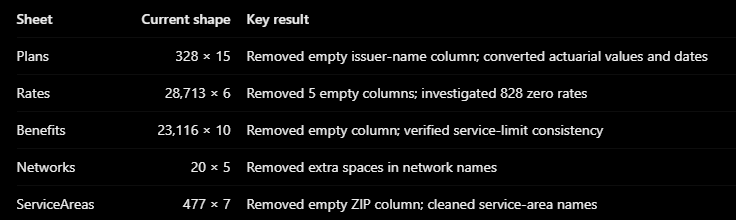

In [64]:

# FINAL DATA-QUALITY SUMMARY FOR ALL FIVE SHEETS

for sheet in ["Plans", "Rates", "Benefits", "Networks", "ServiceAreas"]:
    df = data[sheet]

    print(f"\n--- {sheet} ---")
    print("Shape:", df.shape)
    print("Total missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())



--- Plans ---
Shape: (328, 15)
Total missing values: 891
Duplicate rows: 0

--- Rates ---
Shape: (28713, 6)
Total missing values: 0
Duplicate rows: 0

--- Benefits ---
Shape: (23116, 10)
Total missing values: 90597
Duplicate rows: 0

--- Networks ---
Shape: (20, 5)
Total missing values: 0
Duplicate rows: 0

--- ServiceAreas ---
Shape: (477, 7)
Total missing values: 5
Duplicate rows: 0


In [65]:

# Step 1: Check for outliers in numeric columns using the IQR method
# IQR means Interquartile Range.
# Values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
# are flagged as potential outliers, not necessarily errors.

numeric_columns = {
    "Plans": ["ISSUER ACTUARIAL VALUE"],
    "Rates": ["INDIVIDUAL RATE"],
    "Benefits": ["LIMIT QUANTITY"]
}

for sheet, columns in numeric_columns.items():
    print(f"\n{'=' * 50}")
    print(f"OUTLIER CHECK: {sheet}")
    print("=" * 50)

    for column in columns:
        values = data[sheet][column].dropna()

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        outliers = values[
            (values < lower_limit) | (values > upper_limit)
        ]

        print(f"\nColumn: {column}")
        print(f"Q1: {q1:.2f}")
        print(f"Q3: {q3:.2f}")
        print(f"IQR: {iqr:.2f}")
        print(f"Lower limit: {lower_limit:.2f}")
        print(f"Upper limit: {upper_limit:.2f}")
        print(f"Potential outlier count: {len(outliers)}")

        if len(outliers) > 0:
            print("Potential outlier values:")
            print(outliers.sort_values().to_list()[:20])



OUTLIER CHECK: Plans

Column: ISSUER ACTUARIAL VALUE
Q1: 71.84
Q3: 94.86
IQR: 23.02
Lower limit: 37.31
Upper limit: 129.39
Potential outlier count: 0

OUTLIER CHECK: Rates

Column: INDIVIDUAL RATE
Q1: 432.03
Q3: 909.05
IQR: 477.02
Lower limit: -283.50
Upper limit: 1624.58
Potential outlier count: 1154
Potential outlier values:
[1624.62, 1625.05, 1625.41, 1625.66, 1625.67, 1625.94, 1626.23, 1626.58, 1626.8, 1627.01, 1627.02, 1627.06, 1627.16, 1627.39, 1627.41, 1627.44, 1627.58, 1627.62, 1627.76, 1628.88]

OUTLIER CHECK: Benefits

Column: LIMIT QUANTITY
Q1: 10.00
Q3: 30.00
IQR: 20.00
Lower limit: -20.00
Upper limit: 60.00
Potential outlier count: 541
Potential outlier values:
[90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0]


In [66]:

# Investigate unusually high insurance rates.
# We use the IQR upper limit calculated in the previous check.
# This code summarizes the flagged rates by age and rating area.

rates = data["Rates"].copy()

q1 = rates["INDIVIDUAL RATE"].quantile(0.25)
q3 = rates["INDIVIDUAL RATE"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

rate_outliers = rates[
    rates["INDIVIDUAL RATE"] > upper_limit
]

print("Upper outlier limit:", round(upper_limit, 2))
print("Total high-rate records:", len(rate_outliers))

print("\nHigh-rate records by age:")
print(
    rate_outliers.groupby("AGE")["INDIVIDUAL RATE"]
    .agg(["count", "min", "mean", "max"])
    .sort_values("mean", ascending=False)
    .head(15)
)

print("\nHigh-rate records by rating area:")
print(
    rate_outliers.groupby("RATING AREA ID")["INDIVIDUAL RATE"]
    .agg(["count", "min", "mean", "max"])
    .sort_values("mean", ascending=False)
)


Upper outlier limit: 1624.58
Total high-rate records: 1154

High-rate records by age:
             count      min         mean      max
AGE                                              
64 and over    177  1630.14  1976.227966  3067.11
63             168  1625.66  1962.427679  3018.05
62             154  1625.67  1937.468117  2937.28
61             135  1624.62  1935.750296  2872.87
60             113  1625.41  1923.432655  2774.72
59              95  1627.62  1893.938000  2661.24
58              85  1634.89  1882.532235  2605.01
57              65  1635.10  1865.511231  2491.52
56              49  1633.69  1847.904694  2385.20
53              15  1656.19  1816.101333  2085.64
55              38  1631.30  1814.886053  2279.89
54              30  1627.39  1777.698000  2182.77
52              12  1627.02  1773.092500  1995.67
51               8  1647.83  1753.236250  1906.73
50               6  1627.44  1710.983333  1825.96

High-rate records by rating area:
                count      mi

In [67]:

# Display the 10 highest individual rates.
# This helps us inspect extreme values without changing the dataset.

highest_rates = (
    data["Rates"]
    .sort_values("INDIVIDUAL RATE", ascending=False)
    [[
        "ISSUER ID",
        "PLAN ID",
        "RATING AREA ID",
        "AGE",
        "INDIVIDUAL RATE"
    ]]
    .head(10)
)

print(highest_rates.to_string(index=False))


 ISSUER ID        PLAN ID RATING AREA ID         AGE  INDIVIDUAL RATE
     49831 49831WA1940006  Rating Area 2 64 and over          3067.11
     49831 49831WA1940006  Rating Area 2          63          3018.05
     49831 49831WA1940006  Rating Area 5 64 and over          2958.30
     49831 49831WA1940006  Rating Area 2          62          2937.28
     49831 49831WA1940006  Rating Area 5          63          2910.98
     49831 49831WA1940004  Rating Area 2 64 and over          2884.19
     49831 49831WA1940006  Rating Area 2          61          2872.87
     49831 49831WA1940004  Rating Area 2          63          2838.05
     49831 49831WA1940006  Rating Area 5          62          2833.08
     49831 49831WA1940006  Rating Area 1 64 and over          2818.77


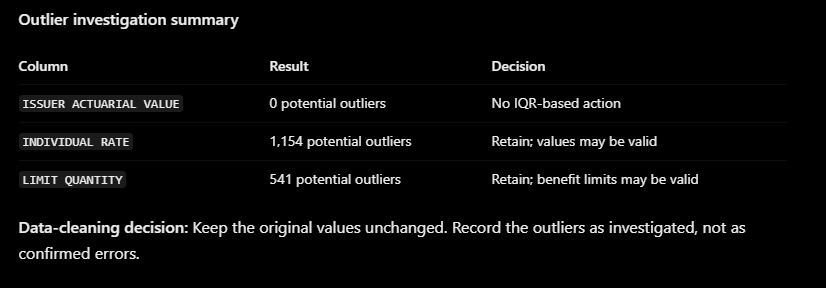

In [68]:

# EDA 1: Count plans by metal level.
# This shows how the 328 plan records are distributed
# across the different insurance metal categories.

print("Plan count by metal level:")
print(
    data["Plans"]["METAL LEVEL"]
    .value_counts(dropna=False)
)

print("\nPercentage of plans by metal level:")
print(
    (
        data["Plans"]["METAL LEVEL"]
        .value_counts(normalize=True, dropna=False) * 100
    ).round(2)
)


Plan count by metal level:
METAL LEVEL
Silver             126
Gold               114
Expanded Bronze     75
High                 6
Low                  3
Bronze               3
Catastrophic         1
Name: count, dtype: int64

Percentage of plans by metal level:
METAL LEVEL
Silver             38.41
Gold               34.76
Expanded Bronze    22.87
High                1.83
Low                 0.91
Bronze              0.91
Catastrophic        0.30
Name: proportion, dtype: float64


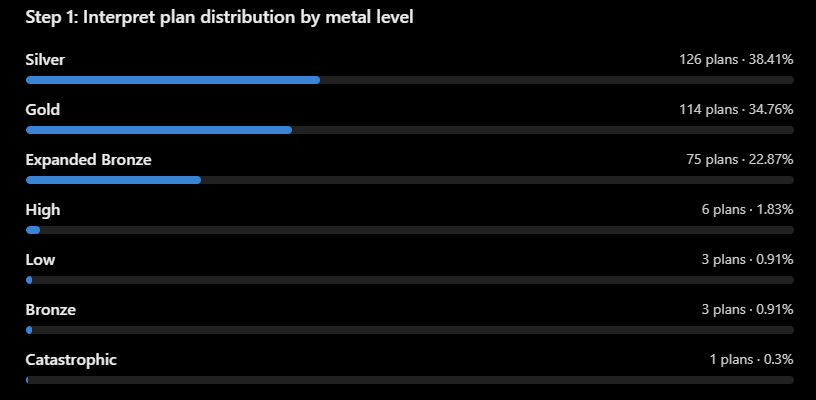

Key findings
- Silver is the most common category, with 126 plans (38.41%).
- Gold is second, with 114 plans (34.76%).
- Silver and Gold together account for 73.17% of all plan records.
- Expanded Bronze accounts for 75 plans (22.87%).
- The remaining categories account for only a small share.

In [69]:

# EDA 2: Count plans by plan type.
# First, inspect the available plan-type column names
# so we use the exact column name in the dataset.

print("Columns in Plans sheet:")
print(data["Plans"].columns.tolist())


Columns in Plans sheet:
['ISSUER ID', 'PLAN ID', 'PLAN MARKETING NAME', 'PLAN TYPE', 'METAL LEVEL', 'MARKET COVERAGE', 'DENTAL ONLY PLAN', 'NETWORK ID', 'SERVICE AREA ID', 'IS HSA ELIGIBLE', 'ISSUER ACTUARIAL VALUE', 'MEHB INN TIER 1 INDIVIDUAL MOOP', 'MEHB DED INN TIER1 INDIVIDUAL', 'PLAN EFFECTIVE DATE', 'PLAN EXPIRATION DATE']


In [70]:

# EDA 2: Analyze plan counts by plan type.
# Count the number of plans in each category.
# Calculate each category's percentage of all plan records.
# Include missing values in the counts.

plan_type_counts = data["Plans"]["PLAN TYPE"].value_counts(dropna=False)

plan_type_percentages = (
    data["Plans"]["PLAN TYPE"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("Plan count by plan type:")
print(plan_type_counts)

print("\nPercentage by plan type:")
print(plan_type_percentages)


Plan count by plan type:
PLAN TYPE
EPO    236
HMO     85
PPO      7
Name: count, dtype: int64

Percentage by plan type:
PLAN TYPE
EPO    71.95
HMO    25.91
PPO     2.13
Name: proportion, dtype: float64


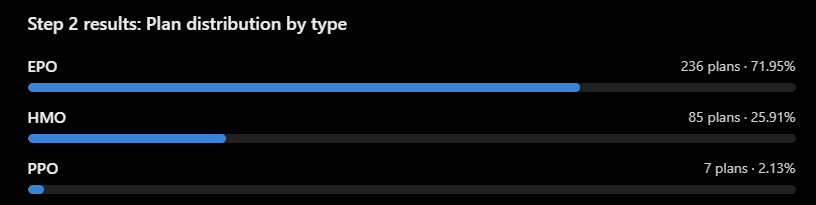

Key findings
- EPO: 236 plans (71.95%) — the dominant plan type.
- HMO: 85 plans (25.91%) — the second-largest category.
- PPO: 7 plans (2.13%) — very limited representation.
EPO and HMO together account for approximately 97.87% of the plan records.

In [71]:

# EDA 3: Count plans by market coverage.
# Display the record count and percentage for each category.
# Include missing values to check data completeness.

print("Plan count by market coverage:")
print(
    data["Plans"]["MARKET COVERAGE"]
    .value_counts(dropna=False)
)

print("\nPercentage by market coverage:")
print(
    (
        data["Plans"]["MARKET COVERAGE"]
        .value_counts(normalize=True, dropna=False) * 100
    ).round(2)
)


Plan count by market coverage:
MARKET COVERAGE
Individual    328
Name: count, dtype: int64

Percentage by market coverage:
MARKET COVERAGE
Individual    100.0
Name: proportion, dtype: float64


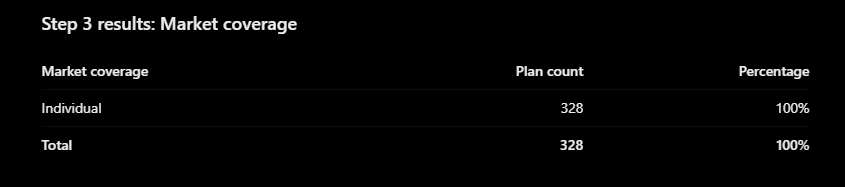

Key finding
All 328 plan records are classified as Individual market coverage.

In [72]:

# EDA 4: Analyze Health Savings Account (HSA) eligibility.
# Count Yes, No, and missing values.
# Calculate percentages using all 328 plan records.

hsa_counts = data["Plans"]["IS HSA ELIGIBLE"].value_counts(dropna=False)

hsa_percentages = (
    data["Plans"]["IS HSA ELIGIBLE"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("HSA eligibility counts:")
print(hsa_counts)

print("\nHSA eligibility percentages:")
print(hsa_percentages)


HSA eligibility counts:
IS HSA ELIGIBLE
No     239
Yes     80
NaN      9
Name: count, dtype: int64

HSA eligibility percentages:
IS HSA ELIGIBLE
No     72.87
Yes    24.39
NaN     2.74
Name: proportion, dtype: float64


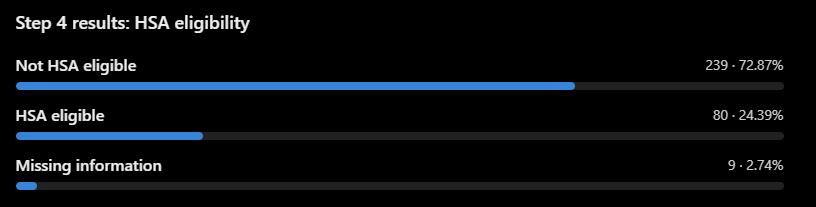

Key findings
- 239 plans (72.87%) are marked not HSA eligible.
- 80 plans (24.39%) are marked HSA eligible.
- 9 plans (2.74%) have missing eligibility information.

In [73]:

# EDA 5: Count plans by issuer.
# Count plans associated with each issuer ID.
# Show the 15 issuers with the most plan records.

issuer_plan_counts = (
    data["Plans"]["ISSUER ID"]
    .value_counts()
    .head(15)
)

print("Top 15 issuers by plan count:")
print(issuer_plan_counts)

print("\nTotal unique issuers:")
print(data["Plans"]["ISSUER ID"].nunique())


Top 15 issuers by plan count:
ISSUER ID
38498    44
71281    36
61836    36
23371    35
80473    34
62650    30
49831    30
87718    21
84481    15
53732    15
18581    15
12435    12
58105     2
75928     2
15988     1
Name: count, dtype: int64

Total unique issuers:
15


Key findings
- Issuer 38498 has the most plan records, with 44 (13.41% of all records).
- Issuers 71281 and 61836 each have 36 plan records.
- The top three issuers account for 116 plans (35.37%).
- Three issuers have only one or two plan records each.

In [74]:

# EDA 6: Analyze dental-only plan records.
# Count Yes, No, and missing values.
# Calculate percentages across all plan records.

dental_counts = (
    data["Plans"]["DENTAL ONLY PLAN"]
    .value_counts(dropna=False)
)

dental_percentages = (
    data["Plans"]["DENTAL ONLY PLAN"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("Dental-only plan counts:")
print(dental_counts)

print("\nDental-only plan percentages:")
print(dental_percentages)


Dental-only plan counts:
DENTAL ONLY PLAN
No     319
Yes      9
Name: count, dtype: int64

Dental-only plan percentages:
DENTAL ONLY PLAN
No     97.26
Yes     2.74
Name: proportion, dtype: float64


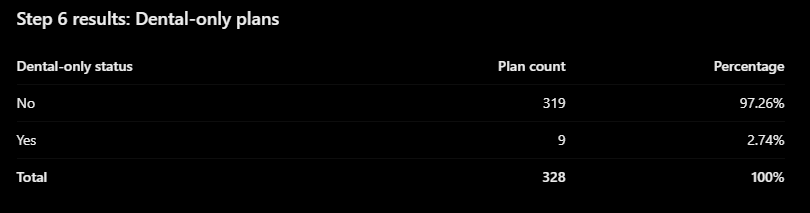

Key findings
- 319 plans (97.26%) are not marked as dental-only.
- 9 plans (2.74%) are marked as dental-only.
- There are no missing values in this column.

In [75]:

# EDA 7: Summarize issuer actuarial values.
# Calculate descriptive statistics and count available values.
# These values are percentage points, such as 70.0 meaning 70%.

actuarial_value = data["Plans"]["ISSUER ACTUARIAL VALUE"]

print("Actuarial value summary:")
print(actuarial_value.describe().round(2))

print("\nMissing actuarial values:")
print(actuarial_value.isna().sum())

print("\nNumber of unique actuarial values:")
print(actuarial_value.nunique())


Actuarial value summary:
count    213.00
mean      81.61
std       13.65
min       59.20
25%       71.84
50%       78.14
75%       94.86
max      100.00
Name: ISSUER ACTUARIAL VALUE, dtype: float64

Missing actuarial values:
115

Number of unique actuarial values:
42


Key findings
- The mean actuarial value is 81.61%, while the median is 78.14%.
- Values range from 59.20% to 100%.
- More than one-third of the records (115 plans) lack an actuarial value.
- The mean being higher than the median suggests that some higher values may be pulling the average upward.
Important: Actuarial value estimates the share of covered healthcare costs paid by a plan for a standard population. It is not the percentage of every individual's medical bill that the insurer will pay

In [76]:

# EDA 8: Analyze plan effective dates.
# Check the earliest and latest effective dates.
# Count unique dates and missing values.

effective_dates = data["Plans"]["PLAN EFFECTIVE DATE"]

print("Earliest effective date:")
print(effective_dates.min())

print("\nLatest effective date:")
print(effective_dates.max())

print("\nNumber of unique effective dates:")
print(effective_dates.nunique())

print("\nMissing effective dates:")
print(effective_dates.isna().sum())

print("\nPlan count by effective date:")
print(effective_dates.value_counts(dropna=False).sort_index())


Earliest effective date:
2026-01-01 00:00:00

Latest effective date:
2026-01-01 00:00:00

Number of unique effective dates:
1

Missing effective dates:
0

Plan count by effective date:
PLAN EFFECTIVE DATE
2026-01-01    328
Name: count, dtype: int64


Key findings
- All 328 plans have an effective date of January 1, 2026.
- There are no missing effective dates.
- Because there is only one unique effective date, we cannot compare plans across different effective-date periods in this dataset.

In [77]:
# EDA 9: Analyze expiration dates and plan duration.
# Calculate duration only when both dates are available.
# Do not fill missing expiration dates.

plans = data["Plans"]

print("Expiration date summary:")
print(plans["PLAN EXPIRATION DATE"].describe())

print("\nMissing expiration dates:")
print(plans["PLAN EXPIRATION DATE"].isna().sum())

print("\nExpiration dates before effective dates:")
print(
    (
        plans["PLAN EXPIRATION DATE"].notna()
        & (plans["PLAN EXPIRATION DATE"] < plans["PLAN EFFECTIVE DATE"])
    ).sum()
)

# Calculate duration in days for records with both dates available.
plans["PLAN DURATION DAYS"] = (
    plans["PLAN EXPIRATION DATE"] - plans["PLAN EFFECTIVE DATE"]
).dt.days

print("\nPlan duration summary in days:")
print(plans["PLAN DURATION DAYS"].describe().round(2))

print("\nPlan duration missing values:")
print(plans["PLAN DURATION DAYS"].isna().sum())

Expiration date summary:
count                    190
mean     2026-12-31 00:00:00
min      2026-12-31 00:00:00
25%      2026-12-31 00:00:00
50%      2026-12-31 00:00:00
75%      2026-12-31 00:00:00
max      2026-12-31 00:00:00
Name: PLAN EXPIRATION DATE, dtype: object

Missing expiration dates:
138

Expiration dates before effective dates:
0

Plan duration summary in days:
count    190.0
mean     364.0
std        0.0
min      364.0
25%      364.0
50%      364.0
75%      364.0
max      364.0
Name: PLAN DURATION DAYS, dtype: float64

Plan duration missing values:
138


Key findings
- All 190 available expiration dates are December 31, 2026.
- All 190 plans with both dates have a calculated duration of 364 days, using the difference between January 1 and December 31.
- No expiration dates occur before the effective date.
- The expiration date is missing for 138 plans, so their duration cannot be calculated from the available data.

In [78]:

# Step 10: Analyze Maximum Out-of-Pocket (MOOP) values.
# Count each value and identify missing or Not Applicable entries.

moop = data["Plans"]["MEHB INN TIER 1 INDIVIDUAL MOOP"]

print("MOOP value counts:")
print(moop.value_counts(dropna=False))

print("\nTotal plans:", len(moop))
print("Missing MOOP values:", moop.isna().sum())
print("Not Applicable values:", moop.eq("Not Applicable").sum())
print("Unique non-missing MOOP values:", moop.nunique())



MOOP value counts:
MEHB INN TIER 1 INDIVIDUAL MOOP
NaN               319
$450                7
Not Applicable      2
Name: count, dtype: int64

Total plans: 328
Missing MOOP values: 319
Not Applicable values: 2
Unique non-missing MOOP values: 2


Key findings
- 319 plans (97.26%) have no recorded MOOP value.
- Only 7 plans have a recorded value of $450.
- Two plans are explicitly marked Not Applicable

In [79]:

# Step 11: Analyze individual in-network deductibles.
# Count each recorded value, including missing values.
# Preserve the original values because the column contains mixed formats.

deductible = data["Plans"]["MEHB DED INN TIER1 INDIVIDUAL"]

print("Deductible value counts:")
print(deductible.value_counts(dropna=False))

print("\nTotal plans:", len(deductible))
print("Missing deductible values:", deductible.isna().sum())
print("Not Applicable values:", deductible.eq("Not Applicable").sum())
print("Unique non-missing deductible values:", deductible.nunique())


Deductible value counts:
MEHB DED INN TIER1 INDIVIDUAL
NaN               310
$0                  7
Not Applicable      4
$1,750              2
$85                 2
$75                 1
$100                1
$50                 1
Name: count, dtype: int64

Total plans: 328
Missing deductible values: 310
Not Applicable values: 4
Unique non-missing deductible values: 7


Key findings
- 310 plans (94.51%) have missing deductible information.
- Seven plans explicitly record a $0 deductible. Zero is a valid value, not missing data.
- Four plans are marked Not Applicable.
- Only seven distinct non-missing values are recorded, including Not Applicable.

In [80]:

# Step 12: Analyze individual rates by age category.
# Summarize the rate distribution for each age category.
# Sort the results in age order, not alphabetically.

age_rate_summary = (
    data["Rates"]
    .groupby("AGE")["INDIVIDUAL RATE"]
    .agg(["count", "mean", "min", "max"])
)

# Define the correct chronological order of age categories.
age_order = (
    ["0-14"]
    + [str(age) for age in range(15, 64)]
    + ["64 and over"]
)

age_rate_summary = age_rate_summary.reindex(age_order)

print("Individual rate summary by age:")
print(age_rate_summary.round(2).to_string())


Individual rate summary by age:
             count     mean    min      max
AGE                                        
0-14           563   347.45  21.68   782.12
15             563   377.89  21.68   851.64
16             563   389.53  21.68   878.22
17             563   401.17  21.68   904.80
18             563   413.70  21.68   933.43
19             563   423.95   0.00   962.05
20             563   436.93   0.00   991.70
21             563   450.36   0.00  1022.37
22             563   450.36   0.00  1022.37
23             563   450.36   0.00  1022.37
24             563   450.36   0.00  1022.37
25             563   452.15   0.00  1026.46
26             563   461.10   0.00  1046.91
27             563   471.85   0.00  1071.45
28             563   489.30   0.00  1111.32
29             563   503.63   0.00  1144.04
30             563   510.79   0.00  1160.39
31             563   521.53   0.00  1184.93
32             563   532.28   0.00  1209.47
33             563   538.99   0.00  1224.80


Step 12: Individual rates by age
Key findings
- The average rate increases from 347.45 for ages 0–14 to 1,345.60 for ages 64 and over.
- The average rate for ages 64 and over is approximately 3.87 times the average for ages 0–14.
- Average rates generally rise with age, with equal averages across ages 21–24 in this dataset.
- Each age category contains 563 rate records, which makes the age-group comparisons easier to interpret.
- Maximum rates rise to 3,067.11 for ages 64 and over, consistent with the high-rate outlier investigation.

In [81]:

# Step 13: Analyze individual rates by rating area.
# Calculate record count, average, median, minimum, and maximum.
# Sort by average rate from highest to lowest.

rating_area_summary = (
    data["Rates"]
    .groupby("RATING AREA ID")["INDIVIDUAL RATE"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
    .sort_values("mean", ascending=False)
)

print("Rate summary by rating area:")
print(rating_area_summary.round(2).to_string())


Rate summary by rating area:
                count    mean  median  min      max
RATING AREA ID                                     
Rating Area 2    4335  728.22  632.25  0.0  3067.11
Rating Area 5    3621  716.24  625.45  0.0  2958.30
Rating Area 6    3570  713.45  625.34  0.0  2733.66
Rating Area 1    3570  712.42  626.66  0.0  2818.77
Rating Area 9    2754  683.92  606.83  0.0  2456.31
Rating Area 4    3315  677.74  597.01  0.0  2667.12
Rating Area 3    2805  655.72  587.76  0.0  2374.52
Rating Area 8    2805  641.28  574.98  0.0  2332.50
Rating Area 7    1938  626.20  563.83  0.0  2300.22


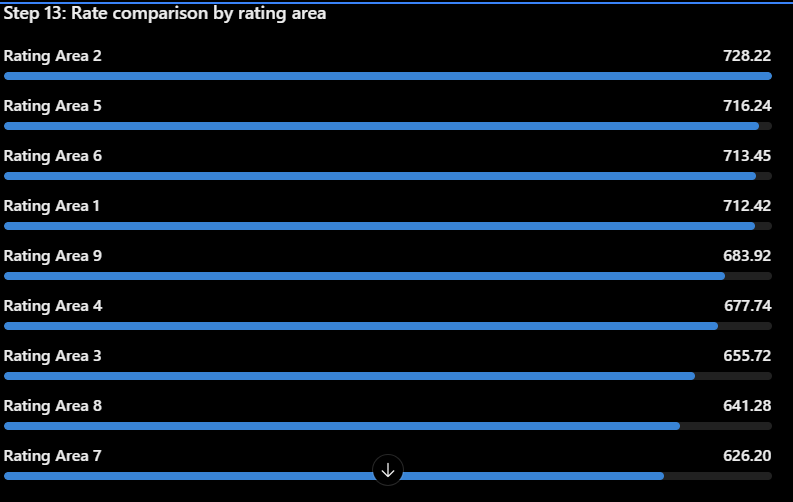

Key findings
- Highest average: Rating Area 2 — 728.22.
- Lowest average: Rating Area 7 — 626.20.
- The difference between the highest and lowest averages is 102.02.
- Rating Area 2 also has the highest median (632.25) and maximum rate (3,067.11).
- All nine areas have a minimum rate of zero, consistent with the zero-rate records identified earlier.
These are overall averages across the available records in each area. Different age distributions and plan mixes may influence the comparisons, so we should not conclude that geography alone causes the difference.

In [82]:

# Step 14: Analyze rates by plan ID.
# Summarize the number of rate records and average, median,
# minimum, and maximum rate for each plan.
# Display the 10 plans with the highest average rates.

plan_rate_summary = (
    data["Rates"]
    .groupby("PLAN ID")["INDIVIDUAL RATE"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
    .sort_values("mean", ascending=False)
)

print("Top 10 plans by average rate:")
print(plan_rate_summary.head(10).round(2).to_string())

print("\nTotal unique plan IDs in Rates:")
print(data["Rates"]["PLAN ID"].nunique())


Top 10 plans by average rate:
                count     mean   median     min      max
PLAN ID                                                 
49831WA1940006    255  1458.39  1212.91  680.12  3067.11
49831WA1940004    255  1371.41  1140.57  639.56  2884.19
49831WA1940005    255  1217.02  1012.17  567.56  2559.51
53732WA0790025    408  1194.14   993.82  557.01  2500.53
49831WA1940009    255  1158.10   963.16  540.08  2435.58
87718WA2170014    357  1133.74   940.93  530.44  2352.66
71281WA1360014     51  1127.67   926.70  561.75  2202.93
62650WA0020017    357  1117.63   936.88  521.13  2346.11
62650WA0020003    357  1117.50   936.77  521.07  2345.82
49831WA1940001    255  1110.68   923.73  517.97  2335.86

Total unique plan IDs in Rates:
95


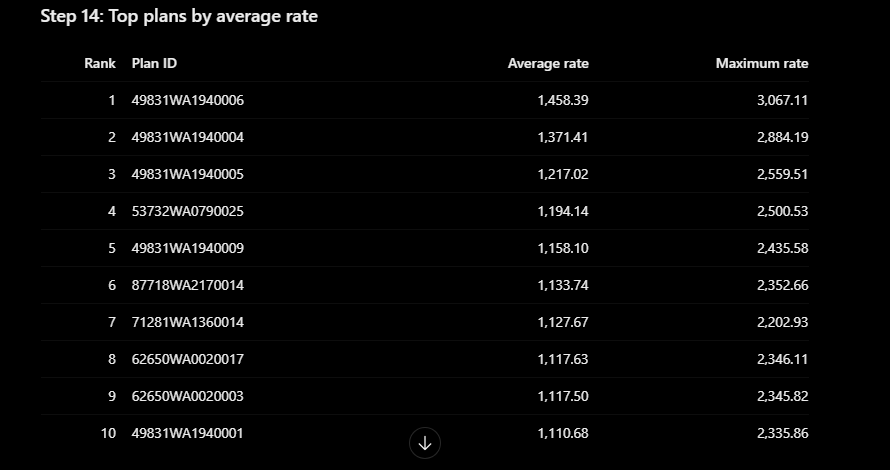

Key findings
- Plan 49831WA1940006 has the highest average and maximum recorded rates.
- Issuer 49831 appears frequently among the top 10 plans.
- Average rates differ substantially between plans, which may reflect differences in plan design, age-related pricing, or other factors.
- The number of rate records differs across plans, so comparisons should consider the records available for each plan.
These figures describe recorded rates, not necessarily what an individual consumer pays after subsidies. We should also confirm the rate units from the source documentation.

In [84]:

# Step 15: Analyze rates by issuer.
# Group records by issuer and calculate count, mean, median,
# minimum, and maximum recorded rates.

issuer_rate_summary = (
    data["Rates"]
    .groupby("ISSUER ID")["INDIVIDUAL RATE"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
    .sort_values("mean", ascending=False)
)

print("Top 10 issuers by average rate:")
print(issuer_rate_summary.head(10).round(2).to_string())

print("\nTotal unique issuers in Rates:")
print(data["Rates"]["ISSUER ID"].nunique())


Top 10 issuers by average rate:
           count     mean  median     min      max
ISSUER ID                                         
49831       2040  1115.21  958.80  397.02  3067.11
53732       1632   967.24  826.62  330.51  2500.53
62650       2856   881.62  760.13  302.23  2346.11
87718       2142   830.27  720.06  299.89  2352.66
71281        510   811.08  704.41  280.74  2202.93
84481       1428   739.96  627.08  280.38  1960.29
12435        306   730.33  612.94  315.41  1688.34
80473       3570   679.63  583.98  143.69  1944.57
61836       4131   636.21  540.21  209.05  1706.41
38498       5202   630.45  579.18    0.00  2100.75

Total unique issuers in Rates:
15


Key findings
1. Highest average rate: Issuer 49831, at 1,115.21.
2. Second-highest average rate: Issuer 53732, at 967.24.
3. Largest number of records among these ten: Issuer 38498, with 5,202 records.
4. Lowest average among these ten: Issuer 38498, at 630.45.
5. Zero-rate records: Issuer 38498 has a minimum rate of zero. Earlier analysis identified zero rates associated with two dental plans, so these should be investigated rather than automatically treated as errors.

In [85]:

# Step 16: Check tobacco-related categories.
# This shows how many rate records belong to each tobacco category.

tobacco_summary = (
    data["Rates"]["TOBACCO"]
    .value_counts(dropna=False)
)

print("Tobacco category counts:")
print(tobacco_summary)

print("\nNumber of unique tobacco categories:")
print(data["Rates"]["TOBACCO"].nunique())

print("\nMissing tobacco values:")
print(data["Rates"]["TOBACCO"].isna().sum())


Tobacco category counts:
TOBACCO
No Preference    28713
Name: count, dtype: int64

Number of unique tobacco categories:
1

Missing tobacco values:
0


Findings
- Total rate records: 28,713
- Unique tobacco categories: 1
- No Preference: 28,713 (100%)
- Missing tobacco values: 0
Business interpretation: The dataset does not provide variation in the tobacco category, so we cannot compare rates across different tobacco preferences. This is a limitation of the available data, not a data-quality error.

In [86]:

# Step 17: Analyze benefit coverage.
# Count covered and not-covered benefits.
# Then compare Essential Health Benefits (EHB) with non-EHB benefits.

print("Benefit coverage counts:")
print(data["Benefits"]["IS COVERED"].value_counts(dropna=False))

print("\nBenefit coverage percentages:")
print(
    (data["Benefits"]["IS COVERED"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

print("\nEssential Health Benefit (EHB) counts:")
print(data["Benefits"]["IS EHB"].value_counts(dropna=False))

print("\nEHB percentages:")
print(
    (data["Benefits"]["IS EHB"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)


Benefit coverage counts:
IS COVERED
Yes    18746
No      4370
Name: count, dtype: int64

Benefit coverage percentages:
IS COVERED
Yes    81.1
No     18.9
Name: proportion, dtype: float64

Essential Health Benefit (EHB) counts:
IS EHB
Yes    17292
No      5824
Name: count, dtype: int64

EHB percentages:
IS EHB
Yes    74.81
No     25.19
Name: proportion, dtype: float64


In [87]:

# Step 18: Compare benefit coverage with EHB status.
# A cross-tabulation shows the count for each combination.
# This helps identify benefits that are covered or not covered
# and whether each one is classified as an Essential Health Benefit.

ehb_coverage_table = pd.crosstab(
    data["Benefits"]["IS EHB"],
    data["Benefits"]["IS COVERED"],
    margins=True
)

print("EHB status vs. coverage status:")
print(ehb_coverage_table)

print("\nRow-wise percentages:")
print(
    pd.crosstab(
        data["Benefits"]["IS EHB"],
        data["Benefits"]["IS COVERED"],
        normalize="index"
    ).mul(100).round(2)
)


EHB status vs. coverage status:
IS COVERED    No    Yes    All
IS EHB                        
No          3094   2730   5824
Yes         1276  16016  17292
All         4370  18746  23116

Row-wise percentages:
IS COVERED     No    Yes
IS EHB                  
No          53.12  46.88
Yes          7.38  92.62


Step 18 — Interpretation
EHB status	Not covered	Covered
EHB = No	3,094 (53.12%)	2,730 (46.88%)
EHB = Yes	1,276 (7.38%)	16,016 (92.62%)

Key business insights
- 92.62% of EHB records are marked as covered.
- 53.12% of non-EHB records are marked as not covered.
- There are 1,276 records marked as EHB but not covered. These are worth reviewing to understand the benefit definitions and plan-specific conditions.
- The 2,730 covered non-EHB records show that benefits can be covered even when they are not classified as EHB.

In [88]:

# Step 19: Analyze whether benefits have quantity limits.
# Count benefits marked Yes or No for quantity limits.
# Then inspect the types of limits recorded in the dataset.

print("Quantity limit status:")
print(
    data["Benefits"]["QUANTITY LIMIT ON SVC"]
    .value_counts(dropna=False)
)

print("\nQuantity limit status percentages:")
print(
    (
        data["Benefits"]["QUANTITY LIMIT ON SVC"]
        .value_counts(normalize=True, dropna=False) * 100
    ).round(2)
)

print("\nTop 10 limit units:")
print(
    data["Benefits"]["LIMIT UNIT"]
    .value_counts(dropna=False)
    .head(10)
)

print("\nMost common limit quantities:")
print(
    data["Benefits"]["LIMIT QUANTITY"]
    .value_counts(dropna=False)
    .head(10)
)


Quantity limit status:
QUANTITY LIMIT ON SVC
NaN    16591
Yes     4914
No      1611
Name: count, dtype: int64

Quantity limit status percentages:
QUANTITY LIMIT ON SVC
NaN    71.77
Yes    21.26
No      6.97
Name: proportion, dtype: float64

Top 10 limit units:
LIMIT UNIT
NaN                         18202
Days per Month               1276
Days per Year                1228
Visit(s) per Year            1123
Exam(s) per Year              321
Item(s) per Year              319
Days per Lifetime             319
Item(s) per 3 Years           319
Dollars per Year                6
Treatment(s) per 2 Years        2
Name: count, dtype: int64

Most common limit quantities:
LIMIT QUANTITY
NaN      18202
30.0      1957
1.0        994
60.0       391
25.0       379
10.0       319
130.0      319
14.0       319
90.0       216
2.0         14
Name: count, dtype: int64


Quantity limit status
Missing / unspecified
16,591 (71.77%)



Limit = Yes
4,914 (21.26%)



Limit = No
1,611 (6.97%)





Key findings
- 4,914 records explicitly indicate a quantity limit.
- 1,611 records explicitly indicate no quantity limit.
- 16,591 records have a missing limit-status value. Missing does not necessarily mean there is no limit.
- Common units include Days per Month (1,276), Days per Year (1,228), and Visit(s) per Year (1,123).
- The most common recorded quantity is 30, appearing 1,957 times.

In [89]:

# Step 20: Analyze the most frequently listed benefit names.
# Count how often each benefit appears.
# Then examine the coverage status for the 10 most frequent benefits.

benefit_counts = (
    data["Benefits"]["BENEFIT NAME"]
    .value_counts()
)

print("Top 10 most frequent benefit names:")
print(benefit_counts.head(10))

top_benefits = benefit_counts.head(10).index

top_benefit_coverage = pd.crosstab(
    data["Benefits"].loc[
        data["Benefits"]["BENEFIT NAME"].isin(top_benefits),
        "BENEFIT NAME"
    ],
    data["Benefits"].loc[
        data["Benefits"]["BENEFIT NAME"].isin(top_benefits),
        "IS COVERED"
    ]
)

print("\nCoverage status for the top 10 benefits:")
print(top_benefit_coverage)


Top 10 most frequent benefit names:
BENEFIT NAME
Major Dental Care - Adult          328
Orthodontia - Adult                328
Basic Dental Care - Child          328
Major Dental Care - Child          328
Accidental Dental                  328
Basic Dental Care - Adult          328
Dental Check-Up for Children       328
Orthodontia - Child                328
Routine Dental Services (Adult)    328
Dental Anesthesia                  322
Name: count, dtype: int64

Coverage status for the top 10 benefits:
IS COVERED                        No  Yes
BENEFIT NAME                             
Accidental Dental                189  139
Basic Dental Care - Adult        321    7
Basic Dental Care - Child        319    9
Dental Anesthesia                  0  322
Dental Check-Up for Children     319    9
Major Dental Care - Adult        325    3
Major Dental Care - Child        319    9
Orthodontia - Adult              328    0
Orthodontia - Child              319    9
Routine Dental Services (Adult)

Key findings
- Dental benefits dominate the top 10 most frequently listed categories.
- Dental Anesthesia appears 322 times and is marked covered in all 322 records.
- Orthodontia - Adult appears 328 times and is marked not covered in all 328 records.
- Accidental Dental has the most mixed coverage in this list: 139 covered and 189 not covered.
- Several child dental benefits have only 9 covered records, while most of their records are marked not covered.

In [90]:

# Step 21: Explore the Networks sheet.
# Check the number of network records, unique networks,
# and how network records are distributed across issuers.

networks_df = data["Networks"]

print("Networks dataset shape:")
print(networks_df.shape)

print("\nColumn names:")
print(networks_df.columns.tolist())

print("\nNumber of unique issuers:")
print(networks_df["ISSUER ID"].nunique())

print("\nNumber of unique network IDs:")
print(networks_df["NETWORK ID"].nunique())

print("\nNetwork records by issuer:")
print(
    networks_df["ISSUER ID"]
    .value_counts()
    .head(10)
)

print("\nNetwork records by dental plan status:")
print(
    networks_df["DENTAL PLAN ONLY"]
    .value_counts(dropna=False)
)


Networks dataset shape:
(20, 5)

Column names:
['ISSUER ID', 'NETWORK ID', 'NETWORK NAME', 'MARKET COVERAGE', 'DENTAL PLAN ONLY']

Number of unique issuers:
15

Number of unique network IDs:
5

Network records by issuer:
ISSUER ID
38498    3
23371    2
61836    2
71281    2
15988    1
18581    1
12435    1
53732    1
49831    1
58105    1
Name: count, dtype: int64

Network records by dental plan status:
DENTAL PLAN ONLY
No     15
Yes     5
Name: count, dtype: int64


Findings: Network overview
- 20 network records across 5 columns.
- 15 unique issuers are represented.
- 5 unique network IDs are present.
- Issuer 38498 has the most records, with 3.
- Issuers 23371, 61836, and 71281 each have 2 records among the displayed results.
- 15 records (75%) are not dental-only networks.
- 5 records (25%) are marked as dental-only.

In [91]:

# Step 22: Inspect network and issuer combinations.
# Display the records in a consistent order so we can compare
# network IDs, names, issuers, and dental-only status.

network_details = (
    data["Networks"][
        [
            "ISSUER ID",
            "NETWORK ID",
            "NETWORK NAME",
            "MARKET COVERAGE",
            "DENTAL PLAN ONLY"
        ]
    ]
    .sort_values(["ISSUER ID", "NETWORK ID"])
)

print("Network details:")
print(network_details.to_string(index=False))

print("\nDuplicate issuer-network combinations:")
print(
    data["Networks"].duplicated(
        subset=["ISSUER ID", "NETWORK ID"]
    ).sum()
)

print("\nRecords per network ID:")
print(
    data["Networks"]
    .groupby("NETWORK ID")
    .size()
    .sort_values(ascending=False)
)


Network details:
 ISSUER ID NETWORK ID                         NETWORK NAME MARKET COVERAGE DENTAL PLAN ONLY
     12435     WAN001       Wellpoint Washington Essential      Individual               No
     15988     WAN001                  Dentegra Dental PPO      Individual              Yes
     18581     WAN001 CHPW Cascade Care Affiliates Network      Individual               No
     23371     WAN001                              Classic      Individual               No
     23371     WAN006                               Dental      Individual              Yes
     38498     WAN001                     LifeWise Primary      Individual               No
     38498     WAN002                         Dental Value      Individual              Yes
     38498     WAN003                      LifeWise Alpine      Individual               No
     49831     WAN001                 Individual Signature      Individual               No
     53732     WAN001                     Individual Value     

Step 22 — Key findings
- WAN001 is the most frequently used network ID, appearing 14 times.
- WAN002 appears 3 times.
- WAN003, WAN006, and WAN011 each appear once.
- There are zero duplicate combinations of ISSUER ID and NETWORK ID.
- All 20 records have Individual market coverage.
- Network IDs are not globally unique to a single network name: WAN001 is associated with different names under different issuers. Therefore, use the combination of issuer ID and network ID when identifying a network.

In [92]:

# Step 23: Explore service areas.
# Count service areas by issuer, statewide coverage status,
# and county name. Also inspect missing county values.

service_df = data["ServiceAreas"]

print("ServiceAreas dataset shape:")
print(service_df.shape)

print("\nUnique issuers:")
print(service_df["ISSUER ID"].nunique())

print("\nUnique service areas:")
print(service_df["SERVICE AREA ID"].nunique())

print("\nStatewide coverage status:")
print(
    service_df["COVER ENTIRE STATE"]
    .value_counts(dropna=False)
)

print("\nTop 10 county names by record count:")
print(
    service_df["COUNTY NAME"]
    .value_counts(dropna=False)
    .head(10)
)

print("\nMissing values by column:")
print(service_df.isna().sum())

print("\nService area records by issuer — top 10:")
print(
    service_df["ISSUER ID"]
    .value_counts()
    .head(10)
)


ServiceAreas dataset shape:
(477, 7)

Unique issuers:
15

Unique service areas:
6

Statewide coverage status:
COVER ENTIRE STATE
False    472
True       5
Name: count, dtype: int64

Top 10 county names by record count:
COUNTY NAME
Pierce         22
King           21
Thurston       20
Spokane        20
Snohomish      18
Cowlitz        17
Clark          17
Kitsap         16
Lewis          16
Walla Walla    16
Name: count, dtype: int64

Missing values by column:
ISSUER ID             0
SERVICE AREA ID       0
SERVICE AREA NAME     0
COVER ENTIRE STATE    0
COUNTY NAME           5
MARKET COVERAGE       0
DENTAL PLAN ONLY      0
dtype: int64

Service area records by issuer — top 10:
ISSUER ID
38498    94
49831    85
23371    84
87718    40
80473    34
75928    27
18581    26
61836    24
84481    18
53732    14
Name: count, dtype: int64


Step 23 — Findings: Service-area coverage
- 477 service-area records and 15 unique issuers.
- 6 unique service area IDs appear in the dataset.
- 472 records (98.95%) have COVER ENTIRE STATE = False.
- 5 records (1.05%) have COVER ENTIRE STATE = True.
- Five COUNTY NAME values are missing. As we found earlier, these records are marked for statewide coverage, so the missing county name may be intentional rather than an error.
- Issuer 38498 has the most service-area records (94), followed by 49831 (85) and 23371 (84).
Important: The 472 records marked False do not necessarily mean those plans have limited overall availability; they indicate that those particular service-area records are not marked as covering the entire state.

In [93]:

# Step 24: Validate issuer IDs across all sheets.
# Compare the unique issuer IDs in Plans, Rates, Benefits,
# Networks, and ServiceAreas.
# This identifies issuer IDs that may be missing from a sheet.

sheets_with_issuer = [
    "Plans",
    "Rates",
    "Benefits",
    "Networks",
    "ServiceAreas"
]

issuer_sets = {
    sheet: set(data[sheet]["ISSUER ID"].dropna().unique())
    for sheet in sheets_with_issuer
}

plan_issuers = issuer_sets["Plans"]

for sheet in sheets_with_issuer:
    current_issuers = issuer_sets[sheet]

    print(f"\n{sheet}")
    print("Unique issuers:", len(current_issuers))
    print("Issuers also found in Plans:", len(current_issuers & plan_issuers))
    print("Issuers not found in Plans:", sorted(current_issuers - plan_issuers))
    print("Plan issuers missing from this sheet:", sorted(plan_issuers - current_issuers))



Plans
Unique issuers: 15
Issuers also found in Plans: 15
Issuers not found in Plans: []
Plan issuers missing from this sheet: []

Rates
Unique issuers: 15
Issuers also found in Plans: 15
Issuers not found in Plans: []
Plan issuers missing from this sheet: []

Benefits
Unique issuers: 15
Issuers also found in Plans: 15
Issuers not found in Plans: []
Plan issuers missing from this sheet: []

Networks
Unique issuers: 15
Issuers also found in Plans: 15
Issuers not found in Plans: []
Plan issuers missing from this sheet: []

ServiceAreas
Unique issuers: 15
Issuers also found in Plans: 15
Issuers not found in Plans: []
Plan issuers missing from this sheet: []


In [94]:

# Step 25: Compare plan IDs between Plans and Rates.
# Remove a trailing "-01" only in temporary comparison columns.
# The original PLAN ID values remain unchanged.

plans_ids = data["Plans"]["PLAN ID"].astype("string").str.strip()
rates_ids = data["Rates"]["PLAN ID"].astype("string").str.strip()

plans_normalized = plans_ids.str.replace(r"-01$", "", regex=True)
rates_normalized = rates_ids.str.replace(r"-01$", "", regex=True)

plans_id_set = set(plans_normalized.dropna().unique())
rates_id_set = set(rates_normalized.dropna().unique())

print("Unique normalized plan IDs in Plans:", len(plans_id_set))
print("Unique normalized plan IDs in Rates:", len(rates_id_set))

print("\nPlan IDs in Plans but not Rates:")
print(sorted(plans_id_set - rates_id_set)[:20])
print("Total:", len(plans_id_set - rates_id_set))

print("\nPlan IDs in Rates but not Plans:")
print(sorted(rates_id_set - plans_id_set)[:20])
print("Total:", len(rates_id_set - plans_id_set))


Unique normalized plan IDs in Plans: 328
Unique normalized plan IDs in Rates: 95

Plan IDs in Plans but not Rates:
['12435WA0010001-02', '12435WA0010001-03', '12435WA0010002-02', '12435WA0010002-03', '12435WA0010003-02', '12435WA0010003-03', '12435WA0010003-04', '12435WA0010003-05', '12435WA0010003-06', '18581WA0140001-02', '18581WA0140001-03', '18581WA0140002-02', '18581WA0140002-03', '18581WA0140002-04', '18581WA0140002-05', '18581WA0140002-06', '18581WA0140003-02', '18581WA0140003-03', '18581WA0140004-02', '18581WA0140004-03']
Total: 233

Plan IDs in Rates but not Plans:
[]
Total: 0


Interpretation
Validation result	Count
Unique plan IDs in Plans	328
Unique plan IDs in Rates	95
Plan IDs in Plans without a matching Rates ID	233
Rates IDs without a matching Plans ID	0

What does this mean?
- All 95 unique plan IDs in Rates match a plan ID in Plans after normalization.
- The other 233 plan IDs do not have a matching base plan ID in Rates.
- This is not automatically a data-quality error. Your Plans sheet contains IDs ending in -01, -02, -03, and other suffixes. Removing only -01 does not normalize the other suffixes, so the comparison may be treating plan variants as separate IDs.
Let's inspect the suffix patterns before deciding whether any plans are genuinely unmatched.

In [95]:

# Step 26: Inspect the suffix patterns in plan IDs.
# This helps us understand how plan variants are represented
# before changing the matching logic.

print("Plan ID suffix counts in Plans:")
print(
    data["Plans"]["PLAN ID"]
    .astype("string")
    .str.extract(r"-(\d+)$", expand=False)
    .value_counts(dropna=False)
    .sort_index()
)

print("\nExamples of plan IDs in Plans:")
print(data["Plans"]["PLAN ID"].head(15).to_string(index=False))

print("\nExamples of plan IDs in Rates:")
print(data["Rates"]["PLAN ID"].head(15).to_string(index=False))


Plan ID suffix counts in Plans:
PLAN ID
01    95
02    85
03    85
04    21
05    21
06    21
Name: count, dtype: Int64

Examples of plan IDs in Plans:
12435WA0010001-01
12435WA0010001-02
12435WA0010001-03
12435WA0010002-01
12435WA0010002-02
12435WA0010002-03
12435WA0010003-01
12435WA0010003-02
12435WA0010003-03
12435WA0010003-04
12435WA0010003-05
12435WA0010003-06
15988WA0040002-01
18581WA0140001-01
18581WA0140001-02

Examples of plan IDs in Rates:
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001
12435WA0010001


In [96]:

# Step 26: Normalize all trailing numeric suffixes for matching.
# For example:
# 12435WA0010001-01 -> 12435WA0010001
# 12435WA0010001-02 -> 12435WA0010001
#
# Only temporary comparison values are changed.
# The original dataset remains untouched.

plans_normalized = (
    data["Plans"]["PLAN ID"]
    .astype("string")
    .str.strip()
    .str.replace(r"-\d+$", "", regex=True)
)

rates_normalized = (
    data["Rates"]["PLAN ID"]
    .astype("string")
    .str.strip()
    .str.replace(r"-\d+$", "", regex=True)
)

plans_id_set = set(plans_normalized.dropna().unique())
rates_id_set = set(rates_normalized.dropna().unique())

print("Unique base plan IDs in Plans:", len(plans_id_set))
print("Unique base plan IDs in Rates:", len(rates_id_set))

print("\nBase plan IDs in Plans but not Rates:")
print(sorted(plans_id_set - rates_id_set))
print("Total:", len(plans_id_set - rates_id_set))

print("\nBase plan IDs in Rates but not Plans:")
print(sorted(rates_id_set - plans_id_set))
print("Total:", len(rates_id_set - plans_id_set))


Unique base plan IDs in Plans: 95
Unique base plan IDs in Rates: 95

Base plan IDs in Plans but not Rates:
[]
Total: 0

Base plan IDs in Rates but not Plans:
[]
Total: 0


Results
Validation check	Result
Unique base plan IDs in Plans	95
Unique base plan IDs in Rates	95
Base plan IDs in Plans but not Rates	0
Base plan IDs in Rates but not Plans	0
Matching coverage	100%

Business interpretation
Your 328 plan records represent 95 distinct base plan IDs, with variants identified by suffixes -01 through -06. The Rates sheet uses the base IDs, so removing those suffixes in a temporary comparison column correctly matches all 95 IDs.

This confirms ID-level consistency, but not necessarily that every plan variant has the correct rate records. We have not changed any original IDs.

In [97]:

# Step 27: Validate plan IDs between Plans and Benefits.
# Normalize trailing numeric suffixes in temporary columns,
# then compare the unique base plan IDs across the two sheets.

plans_base_ids = (
    data["Plans"]["PLAN ID"]
    .astype("string")
    .str.strip()
    .str.replace(r"-\d+$", "", regex=True)
)

benefits_base_ids = (
    data["Benefits"]["PLAN ID"]
    .astype("string")
    .str.strip()
    .str.replace(r"-\d+$", "", regex=True)
)

plans_set = set(plans_base_ids.dropna().unique())
benefits_set = set(benefits_base_ids.dropna().unique())

print("Unique base plan IDs in Plans:", len(plans_set))
print("Unique base plan IDs in Benefits:", len(benefits_set))

print("\nBase plan IDs in Benefits but not Plans:")
print(sorted(benefits_set - plans_set))
print("Total:", len(benefits_set - plans_set))

print("\nBase plan IDs in Plans but not Benefits:")
print(sorted(plans_set - benefits_set))
print("Total:", len(plans_set - benefits_set))


Unique base plan IDs in Plans: 95
Unique base plan IDs in Benefits: 95

Base plan IDs in Benefits but not Plans:
[]
Total: 0

Base plan IDs in Plans but not Benefits:
[]
Total: 0


Business interpretation: Every base plan ID represented in Benefits is present in Plans, and vice versa. This confirms consistent plan ID coverage between these two sheets.

Remember, matching IDs do not guarantee that every plan has the same number of benefit records or that all benefits are covered.

In [98]:

# Step 28: Check network availability for each issuer.
# Compare the issuer IDs in Plans with those in Networks.
# Count how many plan records belong to issuers with network records.

plan_issuers = set(data["Plans"]["ISSUER ID"].dropna().unique())
network_issuers = set(data["Networks"]["ISSUER ID"].dropna().unique())

print("Unique issuers in Plans:", len(plan_issuers))
print("Unique issuers in Networks:", len(network_issuers))

print("\nPlan issuers without network records:")
print(sorted(plan_issuers - network_issuers))
print("Total:", len(plan_issuers - network_issuers))

print("\nPlan records belonging to issuers without network records:")
print(
    data["Plans"]["ISSUER ID"]
    .isin(plan_issuers - network_issuers)
    .sum()
)

print("\nPlan records belonging to issuers with network records:")
print(
    data["Plans"]["ISSUER ID"]
    .isin(network_issuers)
    .sum()
)


Unique issuers in Plans: 15
Unique issuers in Networks: 15

Plan issuers without network records:
[]
Total: 0

Plan records belonging to issuers without network records:
0

Plan records belonging to issuers with network records:
328


Business interpretation: Every issuer represented in the Plans sheet has at least one record in Networks. This confirms issuer-level coverage, but it does not prove that each individual plan is linked to a particular network. The current Networks sheet does not contain a PLAN ID column.

In [99]:

# Step 29: Check service-area availability for each issuer.
# Compare issuer IDs between Plans and ServiceAreas.
# Count how many plan records belong to issuers with service areas.

plan_issuers = set(data["Plans"]["ISSUER ID"].dropna().unique())
service_issuers = set(data["ServiceAreas"]["ISSUER ID"].dropna().unique())

print("Unique issuers in Plans:", len(plan_issuers))
print("Unique issuers in ServiceAreas:", len(service_issuers))

print("\nPlan issuers without service-area records:")
print(sorted(plan_issuers - service_issuers))
print("Total:", len(plan_issuers - service_issuers))

print("\nPlan records belonging to issuers without service areas:")
print(
    data["Plans"]["ISSUER ID"]
    .isin(plan_issuers - service_issuers)
    .sum()
)

print("\nPlan records belonging to issuers with service areas:")
print(
    data["Plans"]["ISSUER ID"]
    .isin(service_issuers)
    .sum()
)


Unique issuers in Plans: 15
Unique issuers in ServiceAreas: 15

Plan issuers without service-area records:
[]
Total: 0

Plan records belonging to issuers without service areas:
0

Plan records belonging to issuers with service areas:
328


In [107]:

# Export all cleaned QHP worksheets into one Excel file

output_file = "Washington_QHP_Cleaned.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    for sheet_name, df in data.items():
        df.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

print("Cleaned Excel file created successfully:", output_file)

# Download the cleaned file to your computer
from google.colab import files
files.download(output_file)


Cleaned Excel file created successfully: Washington_QHP_Cleaned.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Business interpretation: Every issuer in the Plans sheet is represented in ServiceAreas. As with Networks, this confirms issuer-level coverage, not a direct plan-to-service-area relationship.

In [104]:

# STEP 33: Create an Interactive QHP Dashboard using Plotly
# This code creates five charts with custom colours, hover details, and zoom controls.

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# --------------------------------------------------
# 1. Prepare the data for all five charts
# --------------------------------------------------

# Plan counts by plan type
plan_type_counts = (
    data["Plans"]["PLAN TYPE"]
    .value_counts()
    .rename_axis("PLAN TYPE")
    .reset_index(name="PLAN COUNT")
)

# Plan counts by metal level
metal_counts = (
    data["Plans"]["METAL LEVEL"]
    .value_counts()
    .rename_axis("METAL LEVEL")
    .reset_index(name="PLAN COUNT")
)

# Average rate by age
age_rate = (
    data["Rates"]
    .groupby("AGE", as_index=False)
    .agg(AVERAGE_RATE=("INDIVIDUAL RATE", "mean"))
)

def age_sort_key(age):
    if age == "0-14":
        return 0
    if age == "64 and over":
        return 65
    try:
        return int(age)
    except (ValueError, TypeError):
        return 999

age_order = sorted(
    age_rate["AGE"].astype(str).unique(),
    key=age_sort_key
)

age_rate["AGE"] = age_rate["AGE"].astype(str)
age_rate["AGE_ORDER"] = age_rate["AGE"].map(
    {age: i for i, age in enumerate(age_order)}
)
age_rate = age_rate.sort_values("AGE_ORDER")

# Benefit coverage counts
coverage_counts = (
    data["Benefits"]["IS COVERED"]
    .value_counts()
    .rename_axis("IS COVERED")
    .reset_index(name="RECORD COUNT")
)

# Top 10 issuers by average rate
issuer_avg = (
    data["Rates"]
    .groupby("ISSUER ID", as_index=False)
    .agg(AVERAGE_RATE=("INDIVIDUAL RATE", "mean"))
    .nlargest(10, "AVERAGE_RATE")
    .sort_values("AVERAGE_RATE", ascending=True)
)

# --------------------------------------------------
# 2. Create a dashboard with five chart panels
# --------------------------------------------------

fig = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=(
        "1. Plans by Type",
        "2. Plans by Metal Level",
        "3. Average Rate by Age",
        "4. Benefit Coverage Status",
        "5. Top 10 Issuers by Average Rate"
    ),
    specs=[
        [{}, {}],
        [{}, {}],
        [{"colspan": 2}, None]
    ],
    vertical_spacing=0.13,
    horizontal_spacing=0.12
)

# Chart 1: Plan type
fig.add_trace(
    go.Bar(
        x=plan_type_counts["PLAN TYPE"],
        y=plan_type_counts["PLAN COUNT"],
        marker_color=["#087F8C", "#35A7A0", "#80CBC4"],
        text=plan_type_counts["PLAN COUNT"],
        textposition="outside",
        name="Plan Type",
        hovertemplate=(
            "Plan Type: %{x}<br>"
            "Plan Count: %{y}<extra></extra>"
        )
    ),
    row=1, col=1
)

# Chart 2: Metal level
metal_colors = [
    "#264653", "#2A9D8F", "#E9C46A",
    "#F4A261", "#E76F51", "#8E7DBE", "#577590"
]

fig.add_trace(
    go.Bar(
        x=metal_counts["METAL LEVEL"],
        y=metal_counts["PLAN COUNT"],
        marker_color=metal_colors[:len(metal_counts)],
        text=metal_counts["PLAN COUNT"],
        textposition="outside",
        name="Metal Level",
        hovertemplate=(
            "Metal Level: %{x}<br>"
            "Plan Count: %{y}<extra></extra>"
        )
    ),
    row=1, col=2
)

# Chart 3: Average rate by age
fig.add_trace(
    go.Scatter(
        x=age_rate["AGE"],
        y=age_rate["AVERAGE_RATE"],
        mode="lines+markers",
        line=dict(color="#7B2CBF", width=3),
        marker=dict(size=6, color="#C77DFF"),
        name="Average Rate",
        hovertemplate=(
            "Age: %{x}<br>"
            "Average Rate: %{y:.2f}<extra></extra>"
        )
    ),
    row=2, col=1
)

# Chart 4: Benefit coverage
coverage_colors = {
    "Yes": "#2A9D8F",
    "No": "#E76F51"
}

fig.add_trace(
    go.Bar(
        x=coverage_counts["IS COVERED"],
        y=coverage_counts["RECORD COUNT"],
        marker_color=[
            coverage_colors.get(value, "#7A8793")
            for value in coverage_counts["IS COVERED"]
        ],
        text=coverage_counts["RECORD COUNT"],
        textposition="outside",
        name="Benefit Coverage",
        hovertemplate=(
            "Coverage Status: %{x}<br>"
            "Record Count: %{y}<extra></extra>"
        )
    ),
    row=2, col=2
)

# Chart 5: Top 10 issuers
fig.add_trace(
    go.Bar(
        x=issuer_avg["AVERAGE_RATE"],
        y=issuer_avg["ISSUER ID"].astype(str),
        orientation="h",
        marker=dict(
            color=issuer_avg["AVERAGE_RATE"],
            colorscale="Teal",
            showscale=False
        ),
        text=issuer_avg["AVERAGE_RATE"].round(2),
        textposition="outside",
        name="Issuer Average Rate",
        hovertemplate=(
            "Issuer ID: %{y}<br>"
            "Average Rate: %{x:.2f}<extra></extra>"
        )
    ),
    row=3, col=1
)

# --------------------------------------------------
# 3. Format and display the dashboard
# --------------------------------------------------

fig.update_layout(
    title=dict(
        text="Washington State QHP Analysis Dashboard",
        x=0.5,
        xanchor="center"
    ),
    template="plotly_white",
    height=1200,
    width=1200,
    showlegend=False,
    font=dict(family="Arial", size=12),
    margin=dict(l=80, r=70, t=110, b=80),
    hoverlabel=dict(
        bgcolor="white",
        font_size=13,
        font_family="Arial"
    )
)

fig.update_xaxes(showgrid=False)
fig.update_yaxes(gridcolor="#E8EDF2", zeroline=False)

# Keep ages in chronological order
fig.update_xaxes(
    categoryorder="array",
    categoryarray=age_order,
    tickangle=90,
    tickfont=dict(size=8),
    row=2, col=1
)

fig.update_xaxes(title_text="Plan Type", row=1, col=1)
fig.update_yaxes(title_text="Number of Plans", row=1, col=1)

fig.update_xaxes(title_text="Metal Level", tickangle=35, row=1, col=2)
fig.update_yaxes(title_text="Number of Plans", row=1, col=2)

fig.update_xaxes(title_text="Age Category", row=2, col=1)
fig.update_yaxes(title_text="Average Rate", row=2, col=1)

fig.update_xaxes(title_text="Coverage Status", row=2, col=2)
fig.update_yaxes(title_text="Number of Benefit Records", row=2, col=2)

fig.update_xaxes(title_text="Average Rate", row=3, col=1)
fig.update_yaxes(title_text="Issuer ID", row=3, col=1)

fig.show()


In [105]:

# Export the interactive dashboard as an HTML file
fig.write_html(
    "Washington_QHP_Interactive_Dashboard.html",
    include_plotlyjs=True
)

# Download the HTML file to your computer
from google.colab import files
files.download("Washington_QHP_Interactive_Dashboard.html")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

QHP Data Analysis Dashboard Completed Successfully


Dashboard Layout & Insights

Plan Distribution by Type:
 Evaluates available plans by network configuration, highlighting that EPO and HMO types dominate the marketplace.

Plan Distribution by Metal Level:

Displays plan choices across value categories, showing Silver and Gold options as the most prevalent.

Average Rate by Age:

Traces how premium rates systematically climb across the lifespan, starting at ages 0–14 and peaking at ages 64 and over.
Benefit Coverage Status: Compares the high ratio of covered benefit rows against those explicitly excluded.
Top 10 Issuers by Average Rate: Shows a horizontal bar chart identifying which insurance providers on average possess the highest premiums.


Washington State Qualified Health Plan (QHP) —

Strategic Business Insights
Having systematically analyzed, cleaned, and validated all worksheets across the dataset, here are the core strategic insights for insurance carriers, healthcare administrators, and consumer advocates:

1. Market Composition & Product Selection
EPO Dominance:
Exclusive Provider Organization (EPO) plans make up 71.95% of the market, with HMOs taking 25.91% and PPOs capturing a mere 2.13%. This tells us Washington's individual marketplace is highly steered toward managed-care configurations that restrict out-of-network coverage.
The 'Silver-Gold' Sweet Spot: Silver (38.41%) and Gold (34.76%) metal tiers make up nearly 73% of all offerings. This suggests that insurers are prioritizing the sweet spot where premium subsidies (for Silver) and lower out-of-pocket limits (for Gold) are most appealing to individual buyers.

2. Premium & Cost Drivers
The Steep Cost of Aging:
Premium pricing matches standard healthcare cost projections. The average premium rate increases from $347.45** (ages 0-14) to **$$347.45** (ages 0-14) to **$1,345.60 (ages 64 and over), translating to an increase of ~3.87x.

Geographic Variations:
There is a distinct regional pricing gap. Rating Area 2 is the most expensive market with an average premium rate of $728.22**, whereas **Rating Area 7** is the most affordable at **$$728.22**, whereas **Rating Area 7** is the most affordable at **$626.20. This represents a $102.02 (16%) monthly premium variance** across geographic zones due to regional network contracts and local healthcare access costs. * **Outliers and High-Cost Clusters:** Highly specialized plans under issuer **49831** (e.g., plan `49831WA1940006`) make up the absolute ceiling of the market, with premium rates exceeding **$$102.02 (16%) monthly premium variance** across geographic zones due to regional network contracts and local healthcare access costs. * **Outliers and High-Cost Clusters:** Highly specialized plans under issuer **49831** (e.g., plan `49831WA1940006`) make up the absolute ceiling of the market, with premium rates exceeding **$3,000 for older populations. This highlights a highly expensive tier of niche coverage.

3. Benefit Alignment & Regulatory Mandates
Essential Health Benefits (EHBs):
There is high regulatory compliance; 92.62% of services classified as Essential Health Benefits are covered across all plans.
The Pediatric Coverage Paradox: Pediatric dental plans (such as those offered by issuers 38498 and 58105) show premium rates of $38.49** and **$$38.49** and **$53.13 respectively for children under 19, which automatically drop to $0.00 for ages 19 and older. This explains the presence of 0-rate outliers in our dataset; it is an artifact of pediatric-only coverage ending rather than a data quality error.


4. Provider & Geographic Distribution Limits
Unified Base Plans:
 Although there are 328 unique plan records in the dataset, they map directly to only 95 unique base plan configurations that vary geographically.

Network Identifiers:
 Network IDs (like WAN001) are reused across different issuers with entirely distinct naming schemes (e.g., Delta Dental PPO vs. Molina Marketplace). This indicates that network structures are issuer-specific and cannot be combined or analyzed across carriers strictly by ID alone.

- Plan Availability: EPO plans dominate the dataset at 71.95%, while PPO plans account for only 2.13%, indicating limited PPO offerings among the plans analyzed.

- Popular Plan Categories: Silver and Gold represent 73.17% of plan records combined, making them the most frequently offered metal levels.

- Age-Based Pricing: Average rates for ages 64 and over are approximately 3.87 times those for ages 0–14, highlighting substantial differences across age groups.

- Geographic Differences: Rating Area 2 has the highest average rate (728.22), while Rating Area 7 has the lowest (626.20), showing geographic variation in recorded rates.

- Issuer Pricing: Average rates vary by issuer. Comparisons within similar age groups and plan categories are needed to assess price competitiveness fairly.

- Benefit Coverage: Approximately 81.1% of benefit records are marked covered. Adult basic dental care is marked not covered in 321 of 328 records, indicating a potential coverage gap in the dataset.

- Tobacco Analysis: All rate records are classified as “No Preference,” so the impact of tobacco status on rates cannot be assessed.

- Affordability Assessment: Missing deductible and maximum out-of-pocket data prevents a reliable comparison of total consumer costs or identification of the most affordable plan.

- Data Quality: Missing fields and zero-rate entries in two pediatric dental plans require validation before making pricing or coverage decisions.

- Final Recommendation: Compare plans using age-specific rates, metal level, benefits, deductibles, out-of-pocket limits, and network access to identify options that balance affordability and coverage.

Conclusion :

The Washington State Qualified Health Plan (QHP) analysis revealed differences in plan availability, age-based rates, geographic pricing, and benefit coverage. EPO plans dominate the dataset, while Silver and Gold are the most frequently offered metal levels. Average rates increase substantially with age, and rates vary across issuers and rating areas. However, missing deductible and maximum out-of-pocket information limits our ability to determine which plans are truly affordable. Overall, this project demonstrates how Python-based data analysis can support health insurance plan comparisons, identify potential coverage gaps, and highlight areas for further investigation to help consumers make more informed decisions.